# `cellarium-ml` demo: BICAN April 2026 freeze data

A demo to show off the new `cellarium.ml.api` module, streamlining interactive work.

Stephen Fleming

2026.09.25

Can run on a laptop, but if using GCS bucket files, much better to run on a google VM due to network bandwidth.

Using deltacells data format, the entire 3.8M cell dataset is 14.8 GB

Highly variable gene selection ("seurat" flavor) can run on the deltacells data format on a T4 GPU in under 2.5 mins. "seurat_v3" flavor runs in 5 mins.

PCA on 4k highly variable genes can be run in 1 min after a 2.5 min pass through the data to compute z-scoring statistics.

The way this demo works is either by having files local, or by pointing at a google bucket with files.
If you have a list of h5ad files anywhere else, you can simply input the paths as a list for the `h5ad_paths` when instantiating `CellariumData`.

This is a data extract created by Cellarium Nexus, containing 3.86M cells.

In [1]:
# can choose whether to run on CPU or MPS or CUDA

ACCELERATOR = "cuda"  # should be in ["cpu", "mps", "cuda"]
NUM_DATALOADER_WORKERS = 12  # this works well on an n1-standard-16 with 16 vCPUs: adjust based on hardware

## Imports

In [2]:
import cellarium.ml.api as cml

import pandas as pd
import scanpy as sc
sc.set_figure_params(fontsize=14, vector_friendly=True)

import matplotlib.pyplot as plt
%matplotlib inline

/home/sfleming/miniconda3/envs/cellarium/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Deltacells conversion

Shows local h5ad conversion to deltacells format tile datastore.

You can also do this with a `deltacells` command line command, see https://cellarium-ai.github.io/deltacells/convert.html#converting-from-and-to-google-cloud-storage

In [3]:
# adata = sc.read_h5ad("/home/sfleming/data/extract_000000.h5ad")
# adata.obs.columns.tolist()

In [4]:
# cols_to_exclude = [
#  'assay_ontology_term_id',
#  'cell_barcode',
#  'mmc_class_name',
#  'mmc_cluster_name',
#  'mmc_group_name',
#  'mmc_neighborhood_name',
#  'mmc_subclass_name',
#  'prefix',
#  'self_reported_ethnicity',
#  'self_reported_ethnicity_ontology_term_id',
# ]

In [5]:
# import glob

# cml.create_deltacells_dataset(
#     h5ad_paths=glob.glob("/home/sfleming/data/extract*.h5ad"),
#     output="/home/sfleming/data/deltacells_output",
#     tile_size=10000,
#     obs_exclude=cols_to_exclude,
#     overwrite=True,
# )

## Data setup

In [6]:
# set up datamodule: can take a minute for hundreds of files if you are using h5ads

cdata = cml.CellariumData(
    # h5ad_paths=glob.glob("/home/sfleming/data/extract*.h5ad"),  # you can use h5ad files
    deltacells_uri="/home/sfleming/data/deltacells_output",
    total_mrna_umis_column="n_counts",
    var_key="gene_name",
    var_names_make_unique=True,
    datamodule_num_workers=NUM_DATALOADER_WORKERS,
)
cdata

CellariumData(shape [3857513, 38094], obsm keys: [], obs_computed keys: [], hvg_set=False)

## Highly variable gene selection

In [7]:
# run highly variable gene selection

hvg_df = cml.pp.highly_variable_genes(
    cdata,
    n_top_genes=4000,
    flavor="seurat_v3",
    accelerator=ACCELERATOR,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1      | train
-------------------------------------------------------
1         Trainable params
0         Non-trainable params
1         Total params
0.000     Total estimated model params size (MB)
3         Modules in train mode
0         Modules in eval mode


Epoch 1: 100%|██████████| 942/942 [02:44<00:00,  5.72it/s]


In [8]:
# a side-effect of running highly_variable_genes is that cdata.hvg stores the result

cdata.hvg

gene
MALAT1         False
KCNIP4         False
RBFOX1         False
PHACTR1        False
PCDH9          False
               ...  
TRAJ60         False
FAM90A23       False
IGHVII-44-2    False
PRR23D2        False
TRGJP          False
Name: highly_variable, Length: 38094, dtype: bool

In [9]:
cdata.hvg.sum()

4000

In [10]:
# the result is also in hvg_df

hvg_df.head()

,highly_variable_rank,variances_norm,highly_variable
gene,,,
NPY,0.0,120.928216,True
FLT1,1.0,94.096297,True
TRPC3,2.0,76.944936,True
SLC5A7,3.0,76.536242,True
MITA1,4.0,74.356028,True


## PCA

In [11]:
# run PCA

cml.tl.pca(
    cdata,
    n_components=100,
    accelerator=ACCELERATOR,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1      | train
-------------------------------------------------------
1         Trainable params
0         Non-trainable params
1         Total params
0.000     Total estimated model params size (MB)
5         Modules in train mode
0         Modules in eval mode


Epoch 0: 100%|██████████| 942/942 [02:19<00:00,  6.74it/s]


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1      | train
-------------------------------------------------------
1         Trainable params
0         Non-trainable params
1         Total params
0.000     Total estimated model params size (MB)
7         Modules in train mode
0         Modules in eval mode


Epoch 0: 100%|██████████| 942/942 [00:57<00:00, 16.50it/s]


In [12]:
cdata

CellariumData(shape [3857513, 38094], obsm keys: [], obs_computed keys: [], hvg_set=True)
  trained_modules:
    hvg_seurat_v3: HVGSeuratV3(batch_key=None), 2 epochs
    pca: IncrementalPCA(n_components=100, zscore=True, zscore_statistics=normalize_total(target_count=10000, eps=1e-06) > log1p), 1 epochs

In [13]:
cdata.trained_modules["pca"].module

CellariumModule(pipeline = CellariumPipeline(
  (0): NormalizeTotal(target_count=10000, eps=1e-06)
  (1): Filter(filter_list=['DPP10' 'PDE10A' 'NALF1' ... 'DEFB114' 'KRTAP4-11' 'DEFB103B'], ordering=True, allow_missing=False)
  (2): Densify()
  (3): Log1p()
  (4): ZScore(mean_g=tensor([5.6469e+00, 2.2461e+00, 2.1810e+00,  ..., 3.1742e-08, 3.9172e-08,
          6.2976e-08]), std_g=tensor([4.6369e-01, 2.2608e+00, 2.0591e+00,  ..., 6.2344e-05, 7.6935e-05,
          1.2369e-04]), var_names_g=['MALAT1' 'KCNIP4' 'RBFOX1' ... 'IGHVII-44-2' 'PRR23D2' 'TRGJP']), eps=0.0001
  (5): IncrementalPCA()
))

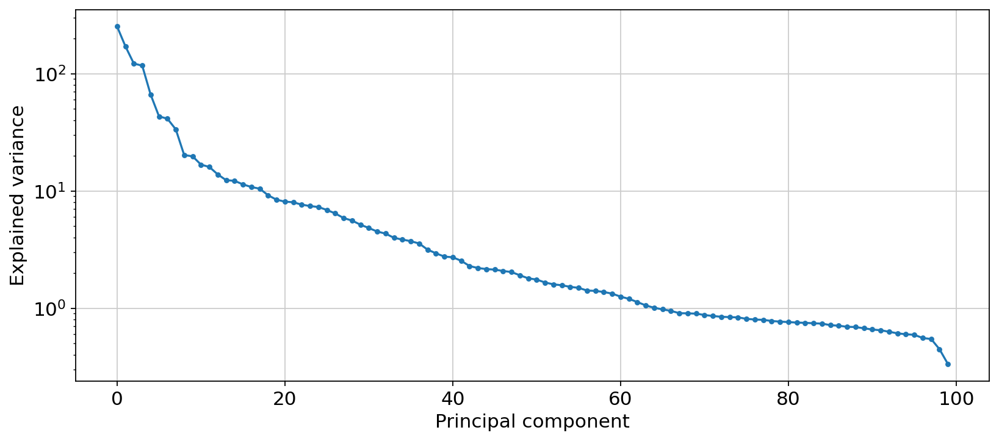

In [14]:
# small example plot of explained variance for principal components

plt.figure(figsize=(12, 5))
plt.semilogy(cdata.trained_modules["pca"].module.model.explained_variance_k, '.-')
plt.xlabel("Principal component")
plt.ylabel("Explained variance")
plt.show()

We now have a PCA module trained, but we have not computed and stored the PCs anywhere yet. For this 4M cell dataset we could, but we might have datasets where storing all the PCs in memory would be prohibitive.

In this demo, we will first use the PCA model to run geometric sketching, and then store a sketched AnnData that has the computed PCs.

## Mini-analysis

I noticed that some cells are labeled with the cell_type "cell".  Let's get cellarium-ml to re-label all cells based on knn from labeled cells.

k-nearest-neighbors are calculated based on that PCA we just computed.

In [15]:
cdata.obs_computed['imputed_cell_type'] = cdata.obs['cell_type'][cdata.obs['cell_type'] != 'cell'].copy()

In [16]:
cdata.obs_computed['imputed_cell_type'].value_counts(dropna=False).head(15)

cell_type
oligodendrocyte                                            1370980
astrocyte                                                   456062
matrix D2 medium spiny neuron                               377726
matrix D1 medium spiny neuron                               365970
oligodendrocyte precursor cell                              194170
L2/3 intratelencephalic projecting glutamatergic neuron     183855
interneuron                                                 154633
microglial cell                                             114227
eccentric medium spiny neuron                                91100
striosomal D1 medium spiny neuron                            87477
striosomal D2 medium spiny neuron                            64056
medium spiny neuron                                          56961
L5 intratelencephalic projecting glutamatergic neuron        49087
L4 intratelencephalic projecting glutamatergic neuron        41690
NaN                                                 

In [17]:
# ask it to propagate labels based on knn
cml.tl.propagate_labels(cdata, labels_key='imputed_cell_type', rep='pca', k=15)

Embedding cells with 'pca':   0%|          | 0/942 [00:00<?, ?batch/s]

Propagating labels: 100%|██████████| 1/1 [00:35<00:00, 35.08s/chunk]


PropagateLabelsResult(key_added='imputed_cell_type_propagated', rep='X_pca', method='exact', n_reference=3818095, n_propagated=39418, agreement=0.97135, n_checked=20000)

In [18]:
print(cdata)

CellariumData(shape [3857513, 38094], obsm keys: ['X_pca'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance'], hvg_set=True)
  trained_modules:
    hvg_seurat_v3: HVGSeuratV3(batch_key=None), 2 epochs
    pca: IncrementalPCA(n_components=100, zscore=True, zscore_statistics=normalize_total(target_count=10000, eps=1e-06) > log1p), 1 epochs


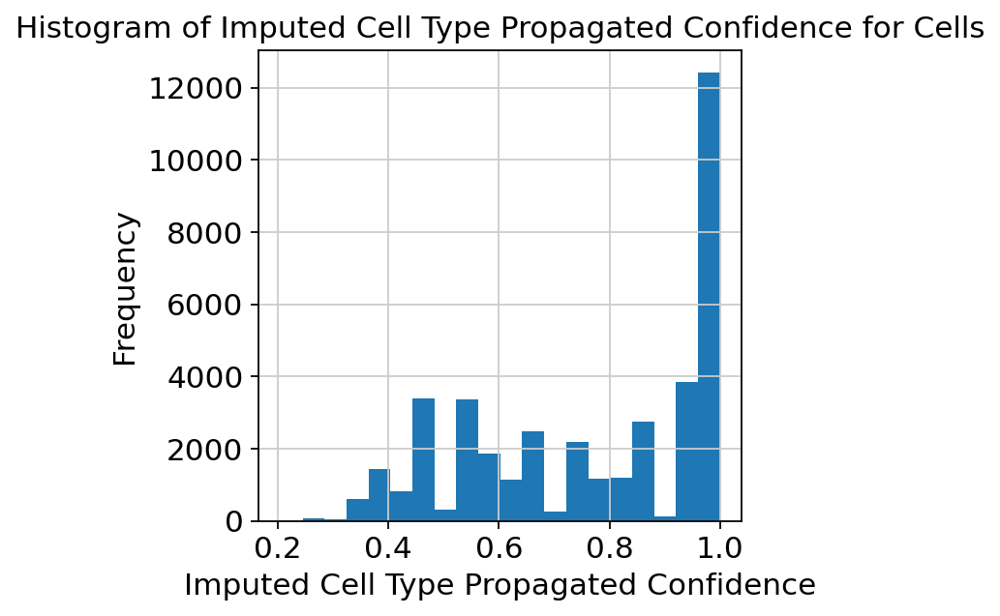

In [19]:
# little histogram of a heuristic label confidence score shows many labels look quite confident
plt.hist(cdata.obs_computed['imputed_cell_type_propagated_confidence'][cdata.obs['cell_type'] == 'cell'], bins=20)
plt.xlabel('Imputed Cell Type Propagated Confidence')
plt.ylabel('Frequency')
plt.title('Histogram of Imputed Cell Type Propagated Confidence for Cells')
plt.show()

## Analysis workflow

Let's pretend that we really are super interested in running cNMF on all the endothelial cells, but we are not totally convinced that we have the endothelial cells labeled correctly, or maybe this is a new dataset and we don't have cell type labels yet.

So let's... cluster the whole dataset, then slice it to endothelial cells, then run cNMF on the endothelial cells.

### Clustering the whole dataset

Running clustering truly at scale, say on 100M cells, is really not so doable.  On 4M cells you could use nvidia RAPIDS if you want the exact answer quickly.  That's not part of this demo though, since I want to show how it would work in a cellarium-ml workflow that really scales to 100M cells.

Here the strategy is: (1) make a geometric sketch of the dataset as an anndata, (2) use scanpy to run Leiden, and (3) project those Leiden labels back to the full dataset.

In [20]:
# 1, make a geometric sketch and take it to anndata in memory

adata = cdata.to_anndata(
    downsample_method="geometric_sketch", 
    target_n_cells=100000, 
    geometric_sketch_kwargs={
        'embedding_module_key': 'pca',
        'n_pcs': 60,
        'accelerator': ACCELERATOR,
    },
)
print(adata)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 2      | train
-------------------------------------------------------
1         Trainable params
1         Non-trainable params
2         Total params
0.000     Total estimated model params size (MB)
4         Modules in train mode
6         Modules in eval mode


Epoch 0: 100%|██████████| 942/942 [01:09<00:00, 13.63it/s, current_cells=2.65e+5, proj_total_cells=2.65e+5, voxel_size_mean=21.00, voxel_size_max=40.70, coarsen_events=84.00, active_voxels=1.99e+5]


AnnData object with n_obs × n_vars = 100000 × 38094
    obs: 'age', 'assay', 'biobank', 'brain_region_abbreviation', 'cell_type', 'cell_type_ontology_term_id', 'cohort', 'data_freeze', 'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_external_id', 'donor_id', 'experiment', 'expression_doublet', 'extraction', 'frac_contamination', 'hbcac_status', 'imputed_sex', 'n_counts', 'neuropath_diagnosis', 'num_genes', 'num_genic_reads', 'num_retained_transcripts', 'num_transcripts', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'pct_utr', 'race', 'scpred_class', 'scpred_sub_class', 'sequencing_assay', 'sex', 'suspension_type', 'tissue', 'tissue_ontology_term_id', 'tissue_type', 'village', 'cellarium_cell_id', 'computed_imputed_cell_type', 'computed_imputed_cell_type_propagated', 'computed_imputed_cell_type_propagated_confidence', 'computed_imputed_cell_type_propagated_distance'
    var: 'gene_id', 'gene_id_raw', 'hgnc_id', 'gene_type', 'gene_v

The second "collection" step obtains the subset count matrix we need, in memory, but it also keeps track of the full-data PCA in an on-disk format so that it can be used later to re-integrate Leiden labels back into the full dataset.

As you can see, this anndata has the requested 100k cells and it also has our full-data PCA embedding in obsm.

Let's first look at a UMAP just because, and then we can run Leiden using scanpy.

In [21]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep='X_pca', method='umap', metric='cosine', n_pcs=60)

In [22]:
sc.tl.umap(adata)

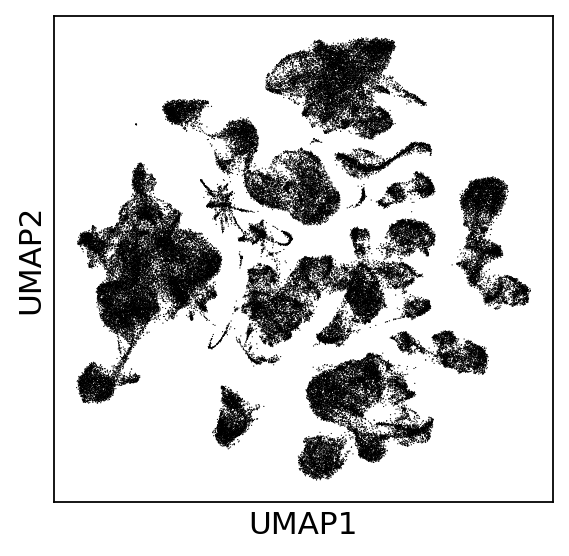

In [23]:
sc.pl.embedding(adata, basis='umap', na_color='k')

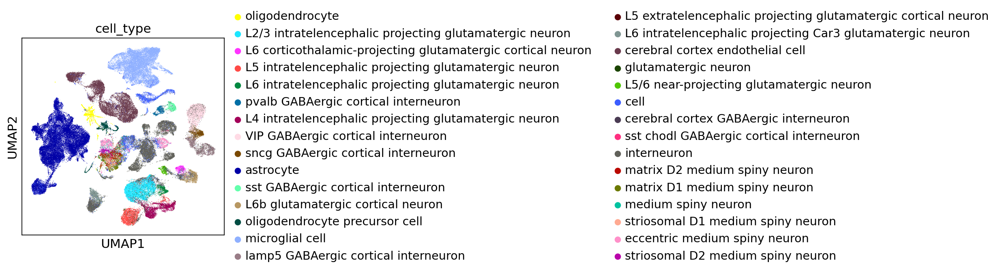

In [24]:
sc.pl.embedding(adata, basis='umap', color='cell_type')

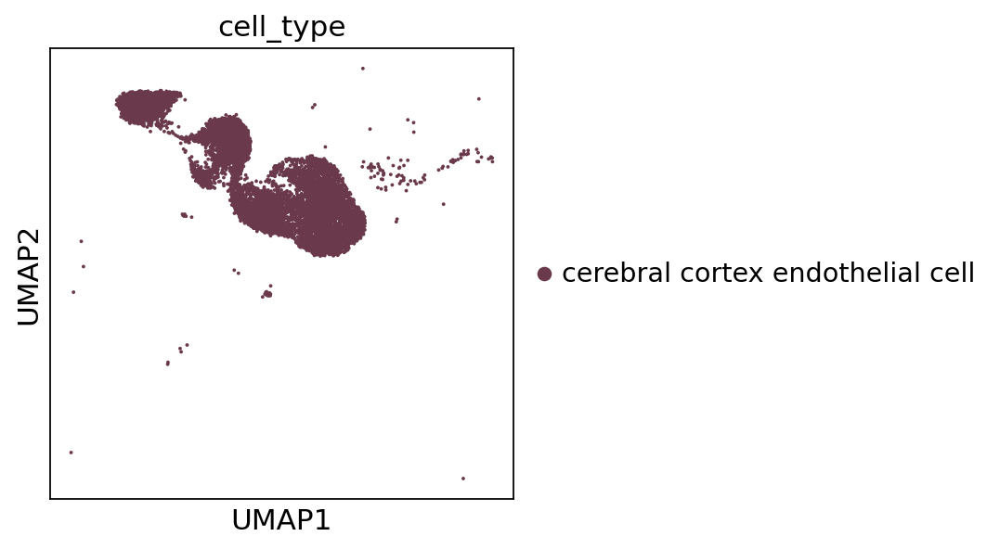

In [25]:
sc.pl.embedding(adata[adata.obs['cell_type'] == 'cerebral cortex endothelial cell'], basis='umap', color='cell_type')

### Re-running clustering

In [26]:
sc.tl.leiden(adata, resolution=0.5, flavor='igraph')

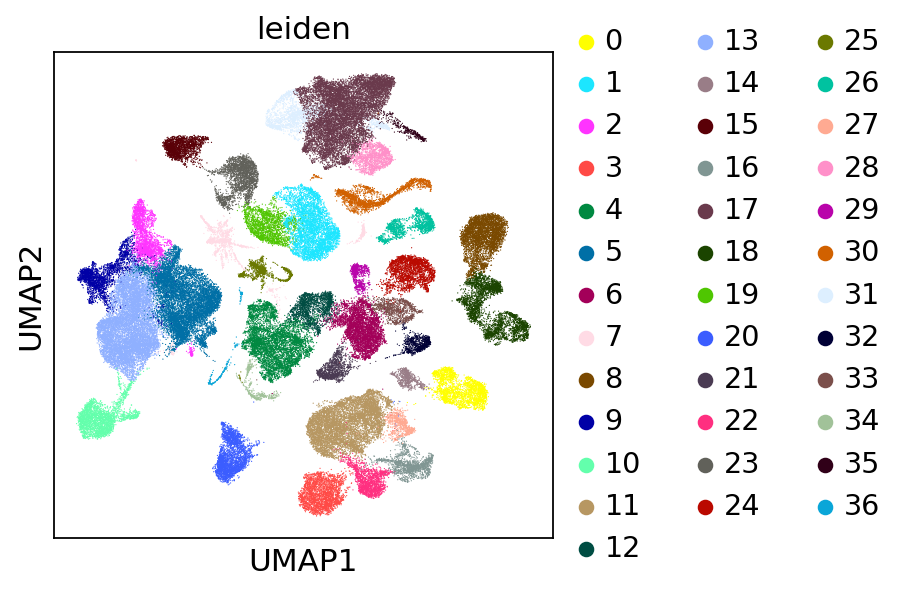

In [27]:
sc.pl.embedding(adata, basis='umap', color='leiden')

In [28]:
mask = adata.obs['computed_imputed_cell_type_propagated'] == 'cerebral cortex endothelial cell'

df = pd.crosstab(
    adata.obs['computed_imputed_cell_type_propagated'][mask], 
    adata.obs['leiden'][mask]
)
df

leiden,1,2,5,7,10,13,15,17,19,23,26,27,28,30,35
computed_imputed_cell_type_propagated,,,,,,,,,,,,,,,
cerebral cortex endothelial cell,4174,1,6,40,1,1,1792,4,1881,2365,1,1,3,89,1


In [29]:
ec_leiden_clusters = df.columns[(df > 1000).any()].tolist()
ec_leiden_clusters

['1', '15', '19', '23']

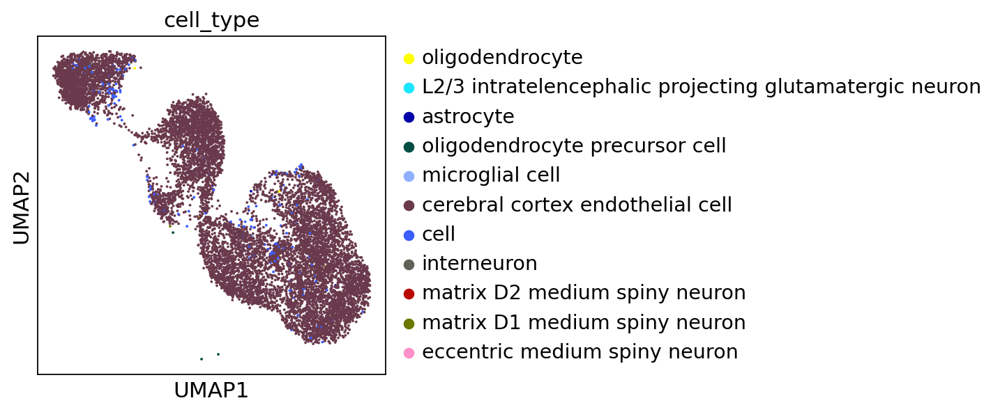

In [30]:
sc.pl.embedding(adata[adata.obs['leiden'].isin(ec_leiden_clusters)], basis='umap', color='cell_type')

In [31]:
vc = adata.obs['cell_type'][adata.obs['leiden'].isin(ec_leiden_clusters)].value_counts()
vc[vc > 0]

cell_type
cerebral cortex endothelial cell                           10014
cell                                                         212
oligodendrocyte                                                8
oligodendrocyte precursor cell                                 3
interneuron                                                    3
astrocyte                                                      2
eccentric medium spiny neuron                                  1
L2/3 intratelencephalic projecting glutamatergic neuron        1
matrix D1 medium spiny neuron                                  1
matrix D2 medium spiny neuron                                  1
microglial cell                                                1
Name: count, dtype: int64

In [32]:
vc = adata.obs['computed_imputed_cell_type_propagated'][adata.obs['leiden'].isin(ec_leiden_clusters)].value_counts()
vc[vc > 0]

computed_imputed_cell_type_propagated
cerebral cortex endothelial cell                           10212
oligodendrocyte                                               11
astrocyte                                                      7
interneuron                                                    5
oligodendrocyte precursor cell                                 3
microglial cell                                                3
eccentric medium spiny neuron                                  1
medium spiny neuron                                            1
matrix D1 medium spiny neuron                                  1
matrix D2 medium spiny neuron                                  1
VIP GABAergic cortical interneuron                             1
L2/3 intratelencephalic projecting glutamatergic neuron        1
Name: count, dtype: int64

It looks like the imputed labeling from above also labeled those "cell"s as ECs, which agrees with this clustering.

Let's say for the sake of argument we want to believe that Leiden clusters 0, 21, and 28 better represent the ECs than the original cell_type designation.

Let's bring these Leiden labels back to the full dataset, since this clustering is just from a sketch.

In [33]:
cdata.update_labels_from_anndata(adata, column='leiden', as_key='leiden')
print(cdata)

CellariumData(shape [3857513, 38094], obsm keys: ['X_pca'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden'], hvg_set=True)
  trained_modules:
    hvg_seurat_v3: HVGSeuratV3(batch_key=None), 2 epochs
    pca: IncrementalPCA(n_components=100, zscore=True, zscore_statistics=normalize_total(target_count=10000, eps=1e-06) > log1p), 1 epochs


Now let's propagate those Leiden labels to the full dataset via knn.

In [34]:
cml.tl.propagate_labels(cdata, labels_key='leiden', rep='pca', k=15)

Propagating labels: 100%|██████████| 76/76 [01:25<00:00,  1.13s/chunk]


PropagateLabelsResult(key_added='leiden_propagated', rep='X_pca', method='exact', n_reference=100000, n_propagated=3757513, agreement=0.98415, n_checked=20000)

In [35]:
cdata.obs_computed['leiden'].value_counts(dropna=False).head()

leiden
NaN    3757513
17       10216
13        9467
5         8997
11        6889
Name: count, dtype: int64

In [36]:
cdata.obs_computed['leiden_propagated'].value_counts(dropna=False).head()

7     1369627
4      963776
5      288740
11     203210
25     193740
Name: count, dtype: int64

### Subclustering

Actually the cerebral cortex endothelial cells look like they might have some interesting structure going on.

Let's subcluster them to show how that is done.

First we can slice cdata to create a CellariumDataView much like an AnnDataView

In [37]:
cdata_ecs = cdata[cdata.obs_computed['leiden_propagated'].isin(ec_leiden_clusters)]
print(cdata_ecs)

CellariumDataView(shape [12760, 38094], obsm keys: ['X_pca'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=False)
  view of 3857513 cells (the root has 3857513)


This happens to be so small that we can put the whole dataset in RAM, which makes everything faster.

In [38]:
cdata_ecs = cdata_ecs.to_ram()
print(cdata_ecs)

Loading cells into memory: 100%|██████████| 386/386 [01:55<00:00,  3.35block/s]


CellariumDataView(shape [12760, 38094], obsm keys: ['X_pca'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=False)
  view of 12760 cells (the root has 3857513)


Let's train a fresh PCA model just on the ECs to show how we can.

In [39]:
cml.pp.highly_variable_genes(
    cdata_ecs,
    n_top_genes=4000,
    flavor="seurat_v3",
    accelerator=ACCELERATOR,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1      | train
-------------------------------------------------------
1         Trainable params
0         Non-trainable params
1         Total params
0.000     Total estimated model params size (MB)
3         Modules in train mode
0         Modules in eval mode


Epoch 1: 100%|██████████| 4/4 [00:00<00:00,  8.85it/s]


,highly_variable_rank,variances_norm,highly_variable
gene,,,
SELE,0.0,19.652309,True
HBB,1.0,19.018007,True
DKK2,2.0,15.708927,True
ENSG00000229618,3.0,15.065933,True
PDZRN4,4.0,14.205474,True
...,...,...,...
TRAJ60,NaN,0.000000,False
FAM90A23,NaN,0.000000,False
IGHVII-44-2,NaN,0.000000,False


In [40]:
cml.tl.pca(
    cdata_ecs, 
    n_components=100, 
    accelerator=ACCELERATOR,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1      | train
-------------------------------------------------------
1         Trainable params
0         Non-trainable params
1         Total params
0.000     Total estimated model params size (MB)
5         Modules in train mode
0         Modules in eval mode


Epoch 0: 100%|██████████| 4/4 [00:00<00:00,  6.75it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1      | train
-------------------------------------------------------
1         Trainable params
0         Non-trainable params
1         Total params
0.000     Total estimated model params size (MB)
7         Modules in train mode
0         Modules in eval mode


Epoch 0: 100%|██████████| 4/4 [00:00<00:00,  5.42it/s]


Turns out this is small enough that I can just put it straight into RAM as an anndata

In [41]:
# this should be pretty fast from an in-memory collection
adata_ecs = cdata_ecs.to_anndata()
print(adata_ecs)

Embedding cells with 'pca': 100%|██████████| 2/2 [00:01<00:00,  1.44chunk/s]


AnnData object with n_obs × n_vars = 12760 × 38094
    obs: 'age', 'assay', 'biobank', 'brain_region_abbreviation', 'cell_type', 'cell_type_ontology_term_id', 'cohort', 'data_freeze', 'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_external_id', 'donor_id', 'experiment', 'expression_doublet', 'extraction', 'frac_contamination', 'hbcac_status', 'imputed_sex', 'n_counts', 'neuropath_diagnosis', 'num_genes', 'num_genic_reads', 'num_retained_transcripts', 'num_transcripts', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'pct_utr', 'race', 'scpred_class', 'scpred_sub_class', 'sequencing_assay', 'sex', 'suspension_type', 'tissue', 'tissue_ontology_term_id', 'tissue_type', 'village', 'cellarium_cell_id', 'computed_imputed_cell_type', 'computed_imputed_cell_type_propagated', 'computed_imputed_cell_type_propagated_confidence', 'computed_imputed_cell_type_propagated_distance', 'computed_in_sketch', 'computed_leiden', 'computed_leiden_propagat

In [42]:
sc.pp.neighbors(adata_ecs, n_neighbors=15, n_pcs=60, method='umap', metric='cosine')

In [43]:
sc.tl.umap(adata_ecs)

In [44]:
sc.tl.leiden(adata_ecs, resolution=0.25, flavor='igraph')

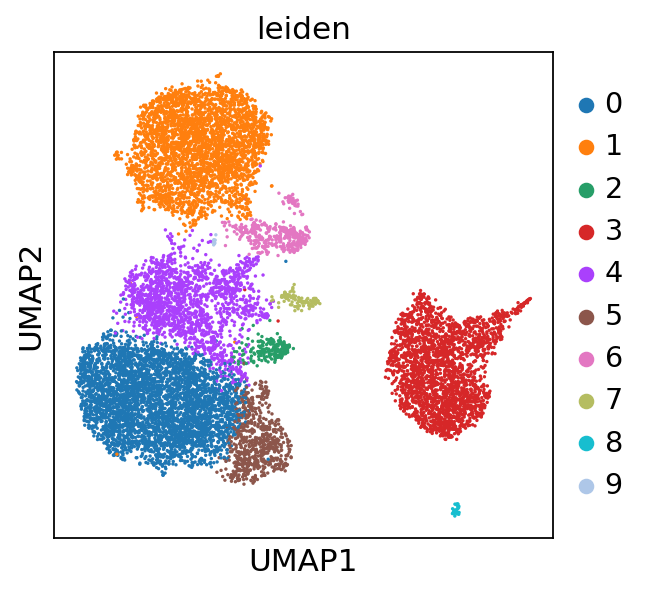

In [45]:
sc.pl.embedding(adata_ecs, basis='umap', color='leiden')

In [46]:
sc.pp.normalize_total(adata_ecs, target_sum=1e4)
sc.pp.log1p(adata_ecs)

In [47]:
sc.tl.rank_genes_groups(adata_ecs, 'leiden', method='t-test')

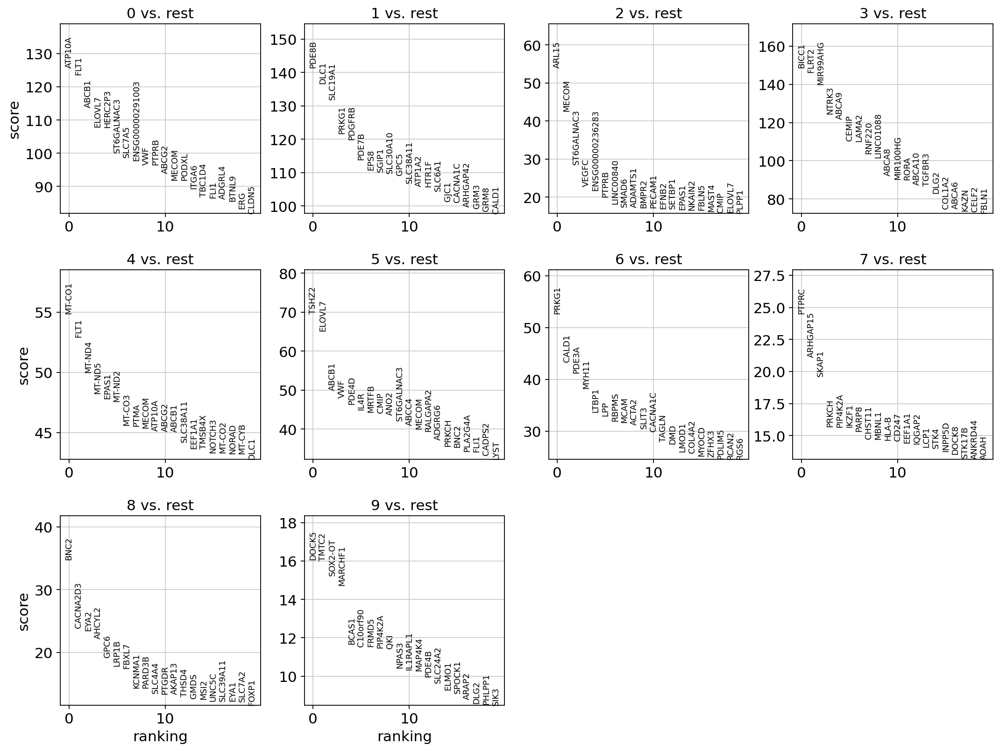

In [48]:
sc.pl.rank_genes_groups(adata_ecs, n_genes=20, sharey=False)

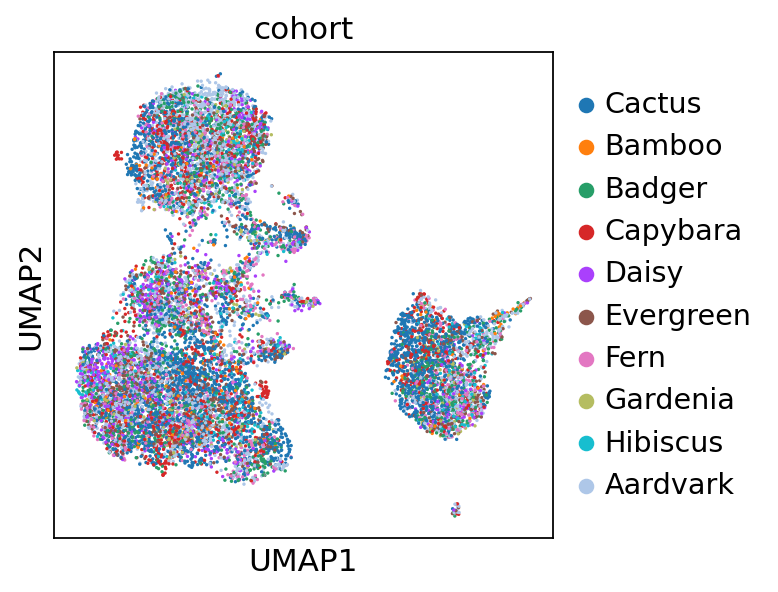

In [49]:
sc.pl.embedding(adata_ecs, basis='umap', color='cohort')

### cNMF

Let's now run cNMF on the ECs

One thing we can do with a small dataset is just put it all in RAM so we're no longer reading from disk.  Let's do that because it makes training as fast as possible.

In [50]:
# compute HVGs as Kotliar does

cml.pp.highly_variable_genes(
    cdata_ecs,
    flavor="kotliar",
    n_top_genes=2000,
    normalize_total=True,
    target_count=1e6,
    log1p=False,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1      | train
-------------------------------------------------------
1         Trainable params
0         Non-trainable params
1         Total params
0.000     Total estimated model params size (MB)
4         Modules in train mode
0         Modules in eval mode


Epoch 0: 100%|██████████| 4/4 [00:00<00:00,  6.20it/s]


,mean,var,fano,fano_fit,fano_ratio,highly_variable
MALAT1,47581.058594,5.182746e+08,10892.455078,11075.756836,0.983450,False
KCNIP4,84.320137,3.381052e+05,4009.780518,202.604874,19.791136,True
RBFOX1,101.828308,3.641392e+05,3576.011475,206.612915,17.307783,True
PHACTR1,235.675232,6.920324e+05,2936.381348,237.253723,12.376545,True
PCDH9,241.592545,5.306548e+05,2196.486328,238.608337,9.205405,True
...,...,...,...,...,...,...
TRAJ60,0.000000,0.000000e+00,NaN,183.301956,NaN,False
FAM90A23,0.000000,0.000000e+00,NaN,183.301956,NaN,False
IGHVII-44-2,0.000000,0.000000e+00,NaN,183.301956,NaN,False
PRR23D2,0.000000,0.000000e+00,NaN,183.301956,NaN,False


In [81]:
nmf_output = cml.tl.cnmf(
    cdata_ecs,
    k_values=list(range(5, 25)),
    n_replicates=100,
    max_epochs=100,
    accelerator=ACCELERATOR,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1.0 M  | train
-------------------------------------------------------
1.0 M     Trainable params
0         Non-trainable params
1.0 M     Total params
4.096     Total estimated model params size (MB)
9         Modules in train mode
0         Modules in eval mode


Epoch 33: 100%|██████████| 4/4 [00:16<00:00,  0.24it/s, rec_error=0.68677, k=5_consensus_q75=4.6036e-05, k=6_consensus_q75=0.00043189, k=7_consensus_q75=0, k=8_consensus_q75=0.0003079, k=9_consensus_q75=0.02817, k=10_consensus_q75=0.052194, k=11_consensus_q75=0.082326, k=12_consensus_q75=0.073342, k=13_consensus_q75=0.069339, k=14_consensus_q75=0.081363, k=15_consensus_q75=0.068605, k=16_consensus_q75=0.083399, k=17_consensus_q75=0.071815, k=18_consensus_q75=0.084014, k=19_consensus_q75=0.090172, k=20_consensus_q75=0.084716, k=21_consensus_q75=0.094904, k=22_consensus_q75=0.099718, k=23_consensus_q75=0.11943, k=24_consensus_q75=0.11286, k_training=20]          Triggering cooldown for k=15 at step=136
Triggering cooldown for k=16 at step=136
Triggering cooldown for k=17 at step=136
Triggering cooldown for k=18 at step=136
Triggering cooldown for k=19 at step=136
Triggering cooldown for k=20 at step=136
Triggering cooldown for k=21 at step=136
Triggering cooldown for k=22 at step=136
Tri

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 99: 100%|██████████| 4/4 [00:04<00:00,  0.85it/s, rec_error=0.74112, k=5_consensus_q75=0.00045982, k=6_consensus_q75=0, k=7_consensus_q75=0, k=8_consensus_q75=0, k=9_consensus_q75=0.00057388, k=10_consensus_q75=0.012632, k=11_consensus_q75=0.030433, k=12_consensus_q75=0.039258, k=13_consensus_q75=0.049478, k=14_consensus_q75=0.055948, k=15_consensus_q75=0.065844, k=16_consensus_q75=0.07869, k=17_consensus_q75=0.069797, k=18_consensus_q75=0.077631, k=19_consensus_q75=0.084667, k=20_consensus_q75=0.081002, k=21_consensus_q75=0.090076, k=22_consensus_q75=0.092718, k=23_consensus_q75=0.10922, k=24_consensus_q75=0.10329, k_training=6]


Reconstruction error: 100%|██████████| 4/4 [00:28<00:00,  7.03s/batch]


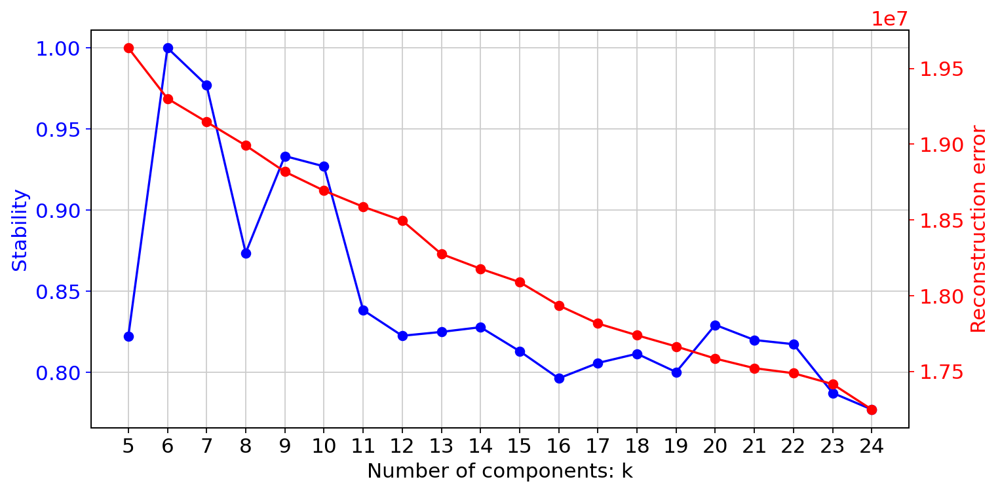

In [82]:
nmf_output.default_k_selection_plot()

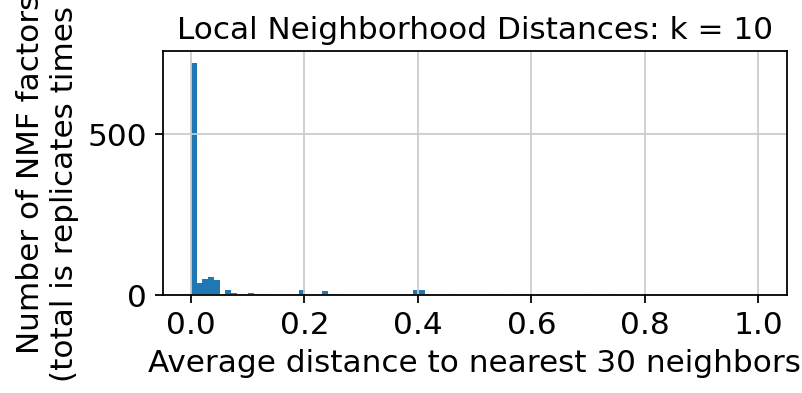

In [83]:
nmf_output.plot_density_histograms(k_values=[10])

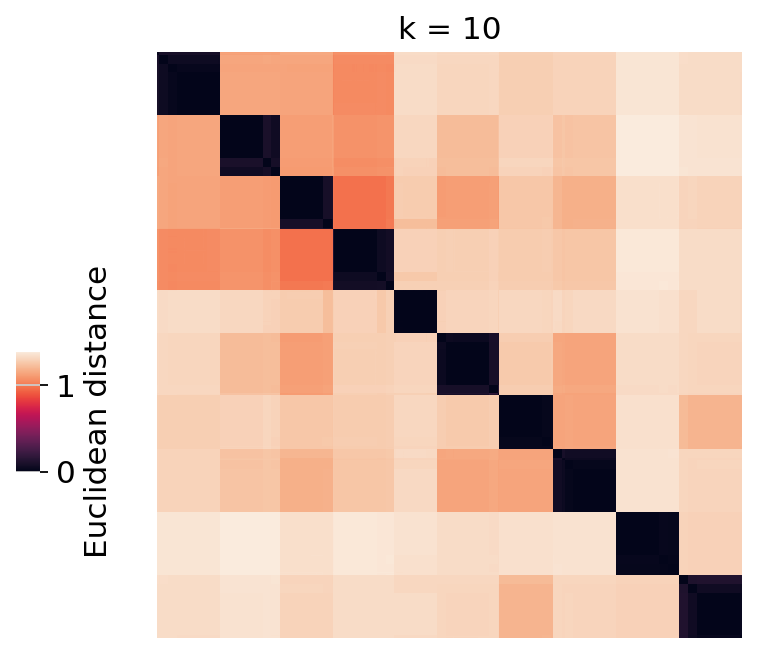

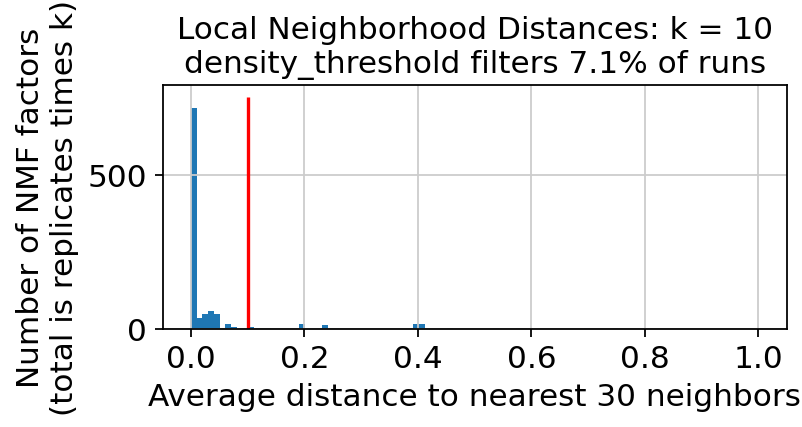

In [84]:
nmf_output.plot_clustermap(k=10, density_threshold=0.1)

In [85]:
# I definitely need a helper method for this

df_gene = pd.DataFrame(
    data=nmf_output.consensus[10]['consensus_D_kg'].t().numpy(), 
    index=cdata_ecs.trained_modules['cnmf'].module.pipeline[0].filter_list,
)
df_gene

,0,1,2,3,4,5,6,7,8,9
KCNIP4,0.000000e+00,0.002216,0.002810,0.000000,0.003139,0.000000,0.000000,0.000801,0.000000,0.000000
RBFOX1,2.233237e-03,0.000063,0.005878,0.000000,0.000108,0.000207,0.000089,0.000146,0.000506,0.000150
PHACTR1,8.401969e-04,0.000186,0.002824,0.000025,0.000593,0.001392,0.000234,0.001455,0.000613,0.001997
PCDH9,1.887589e-03,0.000433,0.006280,0.000039,0.000159,0.000000,0.000298,0.000000,0.001497,0.000027
CSMD1,4.271755e-05,0.000000,0.007405,0.000000,0.001040,0.000128,0.000000,0.000000,0.000402,0.000061
...,...,...,...,...,...,...,...,...,...,...
ENSG00000258444,0.000000e+00,0.000000,0.000010,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000006
LINC02852,0.000000e+00,0.000159,0.000283,0.000073,0.000000,0.000139,0.000068,0.000000,0.000000,0.000031
TRAV26-2,2.937879e-06,0.000000,0.000000,0.000000,0.000000,0.000000,0.000011,0.000000,0.000000,0.000000
PPP4R3C,2.157149e-07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000008,0.000005,0.000000,0.000000


In [87]:
for c in df_gene.columns:
    print(c, ': ', end='')
    print(df_gene.sort_values(by=c, ascending=False)[c].head(10).index.tolist())

0 : ['KCNMA1', 'CDON', 'BNC2', 'EYA1', 'EYA2', 'BMP5', 'C8orf34', 'SLC24A3', 'PALS2', 'PTGDR']
1 : ['ARL15', 'ENSG00000236283', 'EFNB2', 'ALPL', 'GFOD1', 'VEGFC', 'SCN2A', 'SMAD6', 'NTNG1', 'TMTC1']
2 : ['CSMD3', 'CNTNAP2', 'NXPH1', 'PCDH15', 'RALYL', 'DSCAM', 'XKR4', 'NYAP2', 'SLC4A10', 'MEG3']
3 : ['FLRT2', 'ABCA9', 'MIR99AHG', 'NTRK3', 'ABCA10', 'ABCA8', 'RNF220', 'ENSG00000225096', 'SRPX2', 'ABCA6']
4 : ['MYH11', 'MYOCD', 'MCAM', 'TAGLN', 'LMOD1', 'FLNA', 'DGKG', 'AKAP6', 'ACTA2', 'ARHGEF10L']
5 : ['TSHZ2', 'RALGAPA2', 'AFF3', 'LRRC1', 'CMIP', 'IL4R', 'ABCC4', 'MRTFB', 'IL1R1', 'ADGRG6']
6 : ['DLC1', 'SLC30A10', 'SLC19A1', 'PDGFRB', 'GRM3', 'GPC5', 'ATP1A2', 'PDE8B', 'SLC6A1', 'SLC6A12']
7 : ['ELL2', 'PITPNC1', 'AKAP12', 'YBX3', 'ADAMTS9', 'APOLD1', 'ATP1B3', 'MT2A', 'PLEKHG1', 'SLCO4A1']
8 : ['PTPRC', 'IKZF1', 'SKAP1', 'ARHGAP15', 'PIK3R5', 'CD247', 'AOAH', 'SAMD3', 'FYB1', 'SYTL3']
9 : ['SLC39A10', 'SLC7A5', 'CGNL1', 'SPOCK3', 'GPCPD1', 'ABCG2', 'SLCO1A2', 'ATP10A', 'NET1', 'SLC7

In [88]:
d = nmf_output.refit_consensus_factors_zscored_tpm_all_genes(k=10, accelerator=ACCELERATOR)
df_gene_refit = pd.DataFrame(d['factors_kg'].T, index=d['var_names_g'])
df_gene_refit

Refitting k=10:   0%|          | 0/4 [00:00<?, ?batch/s]

Refitting k=10: 100%|██████████| 4/4 [00:02<00:00,  1.62batch/s]


,0,1,2,3,4,5,6,7,8,9
MALAT1,-0.000263,-0.000309,-0.000431,-0.000514,0.001049,-0.000603,0.001022,0.000201,-0.000019,-0.000895
KCNIP4,-0.000069,-0.000053,0.001152,-0.000140,0.000218,-0.000092,-0.000117,-0.000048,0.000033,-0.000105
RBFOX1,0.001178,-0.000019,0.001197,-0.000220,-0.000051,-0.000118,-0.000159,-0.000069,0.000100,-0.000130
PHACTR1,0.000246,-0.000137,0.000666,-0.000349,0.000212,0.000314,-0.000465,0.000226,-0.000002,0.000365
PCDH9,0.001471,-0.000038,0.001903,-0.000303,0.000048,-0.000272,-0.000147,-0.000198,0.000540,-0.000312
...,...,...,...,...,...,...,...,...,...,...
TRAJ60,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
FAM90A23,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
IGHVII-44-2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
PRR23D2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [89]:
for c in df_gene_refit.columns:
    print(c, ': ', end='')
    print(df_gene_refit.sort_values(by=c, ascending=False)[c].head(10).index.tolist())

0 : ['TRPM3', 'PDZRN4-AS1', 'EPHA7', 'SLC13A3', 'SLC24A3', 'PALS2', 'EYA1', 'PRDM6', 'BNC2', 'MAPK4']
1 : ['TRAV10', 'ENSG00000254592', 'LINC01651', 'ARL15', 'NOS1', 'SEMA3G', 'VEGFC', 'ENSG00000236283', 'KCTD12', 'EFNB2']
2 : ['ENSG00000261426', 'ENSG00000259602', 'ENSG00000236958', 'ENSG00000268597', 'OR2V1', 'MARCHF11-DT', 'ENSG00000236858', 'ENSG00000286461', 'NXPH1', 'GABRG3']
3 : ['FLRT2', 'ABCA10', 'ABCA6', 'ABCA9', 'NTRK3', 'ABCA8', 'RNF220', 'PDGFRA', 'MIR99AHG', 'ENSG00000225096']
4 : ['MYH11', 'MCAM', 'TAGLN', 'MYOCD', 'ENSG00000226286', 'SLIT3', 'DGKG', 'SUSD5', 'AKAP6', 'ACTA2']
5 : ['TSHZ2', 'RALGAPA2', 'LRRC1', 'CMIP', 'PDE4D', 'PLA2G4A', 'MRTFB', 'HIPK3', 'ADGRG6', 'IL4R']
6 : ['DLC1', 'PDE8B', 'GRM3', 'MPPED2', 'GPC5', 'MYO1B', 'ATP1A2', 'GRM8', 'SLC6A1', 'PTPRK']
7 : ['ELL2', 'AKAP12', 'APOLD1', 'ADAMTS9', 'PITPNC1', 'ENSG00000251517', 'ENSG00000272703', 'CD59', 'MT2A', 'ENSG00000287561']
8 : ['PTPRC', 'SKAP1', 'CD247', 'AOAH', 'IKZF1', 'IKZF3', 'PRF1', 'ZNF831', 'NKG

In [90]:
nmf_output.compute_loadings(k=10, normalize=True, accelerator=ACCELERATOR)

Loadings for k=10: 100%|██████████| 4/4 [00:01<00:00,  2.11batch/s]


In [91]:
print(cdata_ecs)

CellariumDataView(shape [12760, 38094], obsm keys: ['X_pca', 'X_cnmf_k10'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=True)
  view of 12760 cells (the root has 3857513)
  trained_modules:
    hvg_seurat_v3: HVGSeuratV3(batch_key=None), 2 epochs
    pca: IncrementalPCA(n_components=100, zscore=True, zscore_statistics=normalize_total(target_count=10000, eps=1e-06) > log1p), 1 epochs
    onepass: OnePassMeanVarStd(target_count=1000000.0, eps=1e-06, log1p=False, batch_key=None, normalize_total=True), 1 epochs
    cnmf: AmortizedOnlineNonNegativeMatrixFactorization(k_values=[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24], n_replicates=100, latent_dim=256, max_epochs=100, std_statistics=raw counts), 100 epochs


In [92]:
print(adata_ecs)

AnnData object with n_obs × n_vars = 12760 × 38094
    obs: 'age', 'assay', 'biobank', 'brain_region_abbreviation', 'cell_type', 'cell_type_ontology_term_id', 'cohort', 'data_freeze', 'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_external_id', 'donor_id', 'experiment', 'expression_doublet', 'extraction', 'frac_contamination', 'hbcac_status', 'imputed_sex', 'n_counts', 'neuropath_diagnosis', 'num_genes', 'num_genic_reads', 'num_retained_transcripts', 'num_transcripts', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'pct_utr', 'race', 'scpred_class', 'scpred_sub_class', 'sequencing_assay', 'sex', 'suspension_type', 'tissue', 'tissue_ontology_term_id', 'tissue_type', 'village', 'cellarium_cell_id', 'computed_imputed_cell_type', 'computed_imputed_cell_type_propagated', 'computed_imputed_cell_type_propagated_confidence', 'computed_imputed_cell_type_propagated_distance', 'computed_in_sketch', 'computed_leiden', 'computed_leiden_propagat

In [93]:
adata_ecs.obsm['X_cnmf_k10'] = cdata_ecs.obsm['X_cnmf_k10'].copy()
for c in range(adata_ecs.obsm['X_cnmf_k10'].shape[1]):
    adata_ecs.obs[f'cnmf_{c}_loading'] = adata_ecs.obsm['X_cnmf_k10'][:, c]
print(adata_ecs)

AnnData object with n_obs × n_vars = 12760 × 38094
    obs: 'age', 'assay', 'biobank', 'brain_region_abbreviation', 'cell_type', 'cell_type_ontology_term_id', 'cohort', 'data_freeze', 'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_external_id', 'donor_id', 'experiment', 'expression_doublet', 'extraction', 'frac_contamination', 'hbcac_status', 'imputed_sex', 'n_counts', 'neuropath_diagnosis', 'num_genes', 'num_genic_reads', 'num_retained_transcripts', 'num_transcripts', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'pct_utr', 'race', 'scpred_class', 'scpred_sub_class', 'sequencing_assay', 'sex', 'suspension_type', 'tissue', 'tissue_ontology_term_id', 'tissue_type', 'village', 'cellarium_cell_id', 'computed_imputed_cell_type', 'computed_imputed_cell_type_propagated', 'computed_imputed_cell_type_propagated_confidence', 'computed_imputed_cell_type_propagated_distance', 'computed_in_sketch', 'computed_leiden', 'computed_leiden_propagat

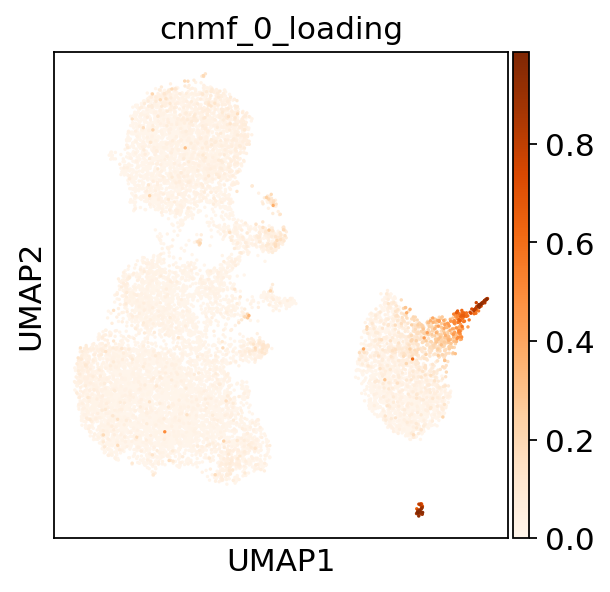

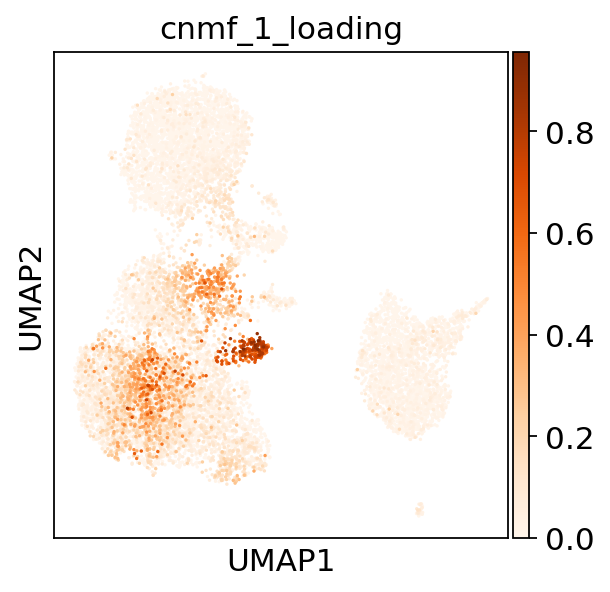

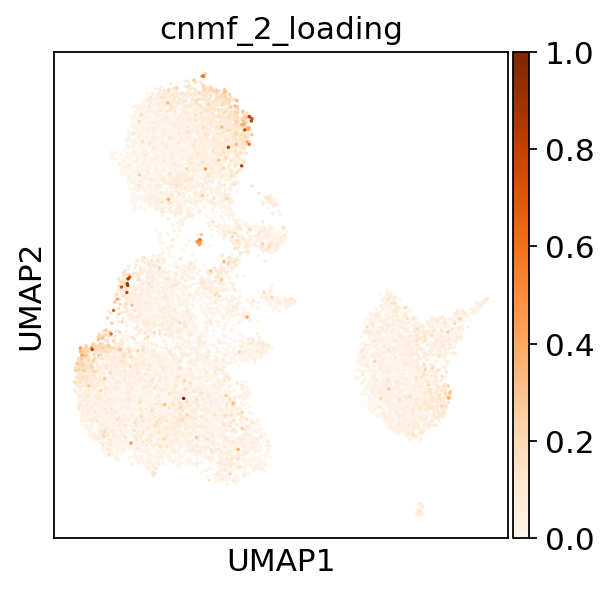

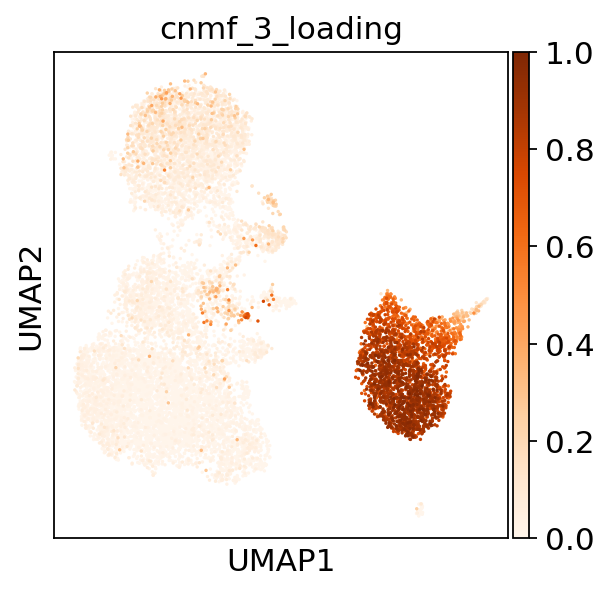

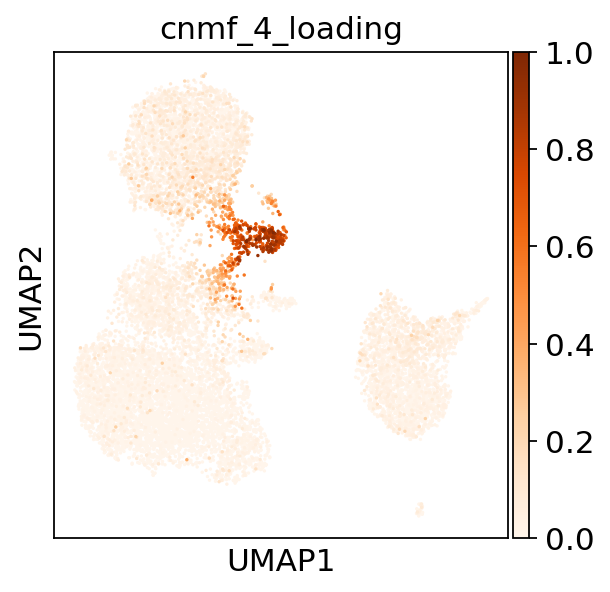

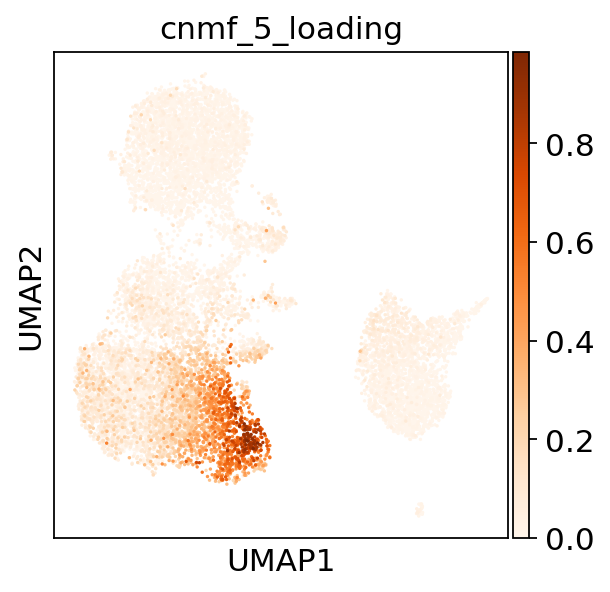

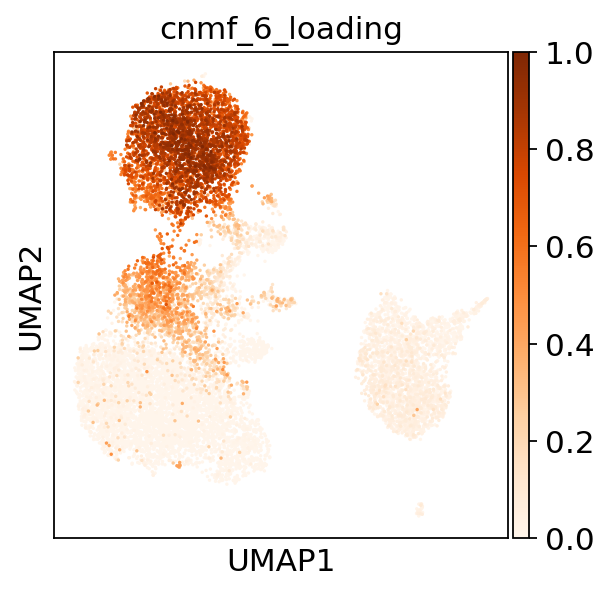

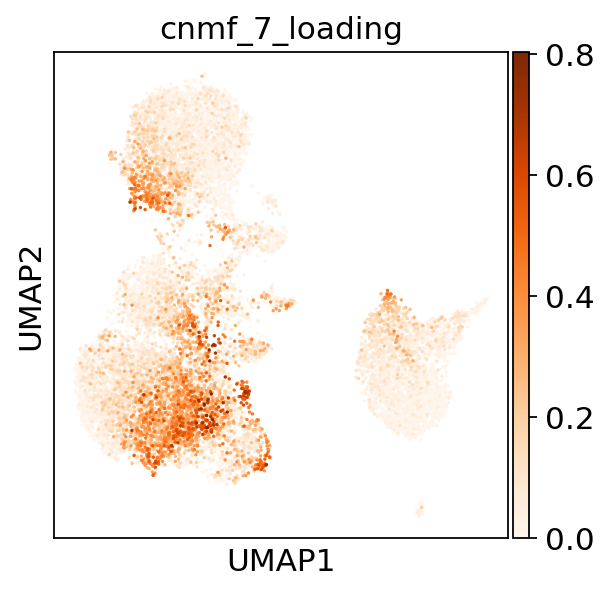

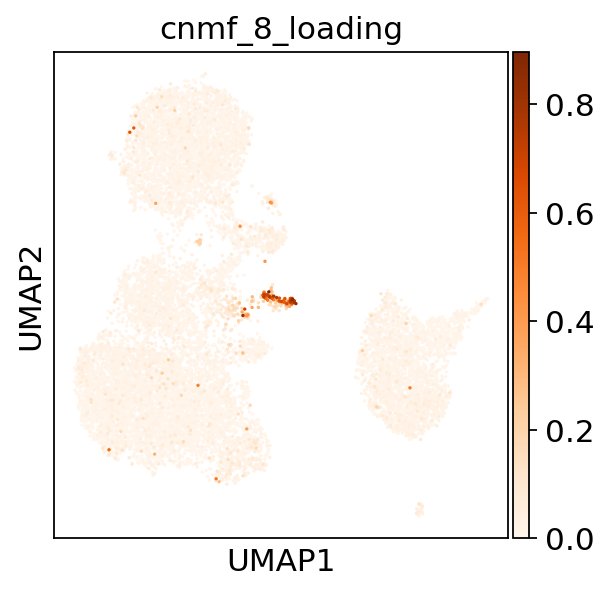

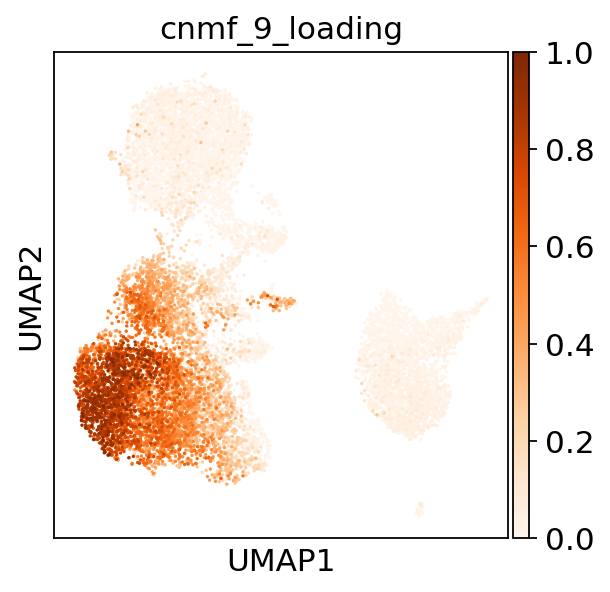

In [94]:
for c in [col for col in adata_ecs.obs.columns if col.startswith('cnmf_')]:
    sc.pl.embedding(adata_ecs, basis='umap', color=c, color_map='Oranges')

## Save and reload a session

In [76]:
print(cdata)

CellariumData(shape [3857513, 38094], obsm keys: ['X_pca'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=True)
  trained_modules:
    hvg_seurat_v3: HVGSeuratV3(batch_key=None), 2 epochs
    pca: IncrementalPCA(n_components=100, zscore=True, zscore_statistics=normalize_total(target_count=10000, eps=1e-06) > log1p), 1 epochs


In [77]:
print(cdata_ecs)

CellariumDataView(shape [12760, 38094], obsm keys: ['X_pca', 'X_cnmf_k10'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=True)
  view of 12760 cells (the root has 3857513)
  trained_modules:
    hvg_seurat_v3: HVGSeuratV3(batch_key=None), 2 epochs
    pca: IncrementalPCA(n_components=100, zscore=True, zscore_statistics=normalize_total(target_count=10000, eps=1e-06) > log1p), 1 epochs
    onepass: OnePassMeanVarStd(target_count=1000000.0, eps=1e-06, log1p=False, batch_key=None, normalize_total=True), 1 epochs
    cnmf: AmortizedOnlineNonNegativeMatrixFactorization(k_values=[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24], n_replicates=50, latent_dim=256, max_epochs=50, std_statistics=raw counts), 50 epochs


`cdata_ecs` is small enough and fast enough I won't even save it.  I'll just save `cdata` for demonstration.

In [78]:
cdata.save('/home/sfleming/analysis_sessions/bican/20261030')

In [79]:
!ls -lh /home/sfleming/analysis_sessions/bican/20261030

total 44M
-rw-rw-r-- 1 sfleming sfleming 334K Oct 30 19:07 hvg.parquet
-rw-rw-r-- 1 sfleming sfleming  15K Oct 30 19:07 manifest.pkl
drwxrwxr-x 2 sfleming sfleming 4.0K Oct 30 19:07 modules
-rw-rw-r-- 1 sfleming sfleming  44M Oct 30 19:07 obs_computed.parquet
drwxrwxr-x 2 sfleming sfleming 4.0K Oct 30 19:07 obsm


In [80]:
cdata = cml.CellariumData.load('/home/sfleming/analysis_sessions/bican/20261030')
print(cdata)

CellariumData(shape [3857513, 38094], obsm keys: ['X_pca'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=True)
  trained_modules:
    hvg_seurat_v3: HVGSeuratV3(batch_key=None), 2 epochs
    pca: IncrementalPCA(n_components=100, zscore=True, zscore_statistics=normalize_total(target_count=10000, eps=1e-06) > log1p), 1 epochs


## scVI

For demonstration purposes

In [ ]:
cml.tl.scvi(
    cdata,
    batch_key="biobank",
    n_latent=64,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1.1 M  | train
-------------------------------------------------------
1.1 M     Trainable params
0         Non-trainable params
1.1 M     Total params
4.315     Total estimated model params size (MB)
34        Modules in train mode
0         Modules in eval mode


Epoch 73:  70%|███████   | 596/848 [01:09<00:29,  8.56it/s, val_loss=1826.5]


In [96]:
cdata.save('/home/sfleming/analysis_sessions/bican/20261030_scvi')

In [3]:
cdata = cml.CellariumData.load('/home/sfleming/analysis_sessions/bican/20261030_scvi')
print(cdata)

CellariumData(shape [3857513, 38094], obsm keys: ['X_pca'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=True)
  trained_modules:
    hvg_seurat_v3: HVGSeuratV3(batch_key=None), 2 epochs
    pca: IncrementalPCA(n_components=100, zscore=True, zscore_statistics=normalize_total(target_count=10000, eps=1e-06) > log1p), 1 epochs
    scvi: SingleCellVariationalInference(batch_key=biobank, n_latent=64, val_size=0.1), 74 epochs


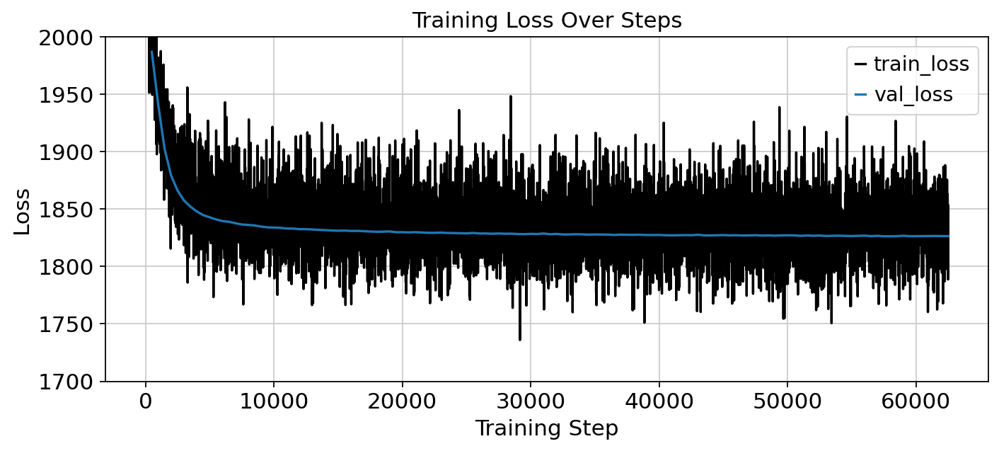

In [6]:
# plot the loss over training steps: currently there is no helper for this

plt.figure(figsize=(10, 4))
logic = cdata.trained_modules["scvi"].history["metric"] == "train_loss"
plt.plot(
    cdata.trained_modules["scvi"].history["step"][logic],
    cdata.trained_modules["scvi"].history["value"][logic],
    label="train_loss",
    color="k",
)
logic = cdata.trained_modules["scvi"].history["metric"] == "val_loss"
plt.plot(
    cdata.trained_modules["scvi"].history["step"][logic],
    cdata.trained_modules["scvi"].history["value"][logic],
    label="val_loss",
)
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training Loss Over Steps")
plt.legend()
plt.ylim([1700, 2000])
plt.show()

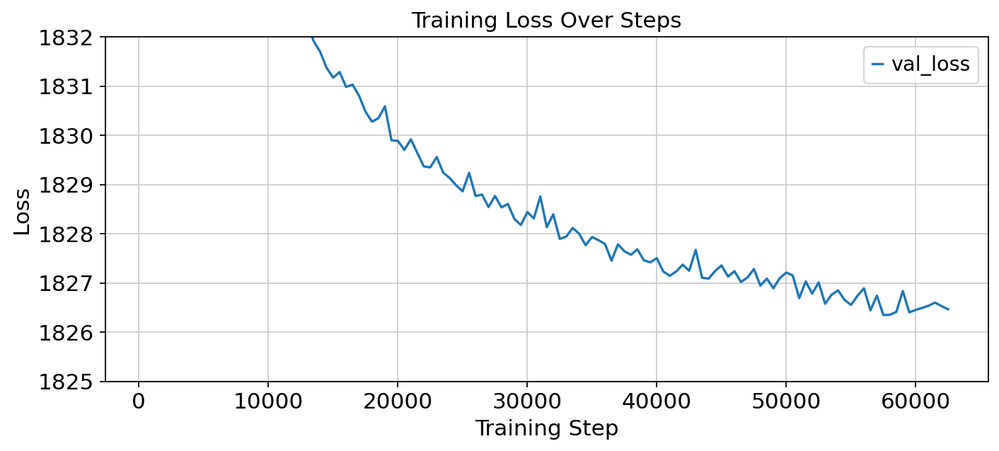

In [7]:
# plot the loss over training steps: currently there is no helper for this

plt.figure(figsize=(10, 4))
logic = cdata.trained_modules["scvi"].history["metric"] == "val_loss"
plt.plot(
    cdata.trained_modules["scvi"].history["step"][logic],
    cdata.trained_modules["scvi"].history["value"][logic],
    label="val_loss"
)
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training Loss Over Steps")
plt.legend()
plt.ylim([1825, 1832])
plt.show()

### UMAP based on scVI

In [8]:
adata = cdata.to_anndata(
    downsample_method='geometric_sketch', 
    target_n_cells=100_000,
    geometric_sketch_kwargs={
        'embedding_module_key': 'scvi',
        'accelerator': ACCELERATOR,
    },
)
print(adata)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1.1 M  | train
-------------------------------------------------------
1         Trainable params
1.1 M     Non-trainable params
1.1 M     Total params
4.315     Total estimated model params size (MB)
3         Modules in train mode
34        Modules in eval mode


Epoch 0: 100%|██████████| 942/942 [01:05<00:00, 14.37it/s, current_cells=2.97e+5, proj_total_cells=2.97e+5, voxel_size_mean=3.560, voxel_size_max=5.240, coarsen_events=37.00, active_voxels=1.95e+5] 


AnnData object with n_obs × n_vars = 100000 × 38094
    obs: 'age', 'assay', 'biobank', 'brain_region_abbreviation', 'cell_type', 'cell_type_ontology_term_id', 'cohort', 'data_freeze', 'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_external_id', 'donor_id', 'experiment', 'expression_doublet', 'extraction', 'frac_contamination', 'hbcac_status', 'imputed_sex', 'n_counts', 'neuropath_diagnosis', 'num_genes', 'num_genic_reads', 'num_retained_transcripts', 'num_transcripts', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'pct_utr', 'race', 'scpred_class', 'scpred_sub_class', 'sequencing_assay', 'sex', 'suspension_type', 'tissue', 'tissue_ontology_term_id', 'tissue_type', 'village', 'cellarium_cell_id', 'computed_imputed_cell_type', 'computed_imputed_cell_type_propagated', 'computed_imputed_cell_type_propagated_confidence', 'computed_imputed_cell_type_propagated_distance', 'computed_in_sketch', 'computed_leiden', 'computed_leiden_propaga

In [ ]:
sc.pp.neighbors(adata, use_rep="X_scvi", method="umap", metric="euclidean")
sc.tl.umap(adata)
adata.obsm["X_scvi_umap"] = adata.obsm["X_umap"].copy()

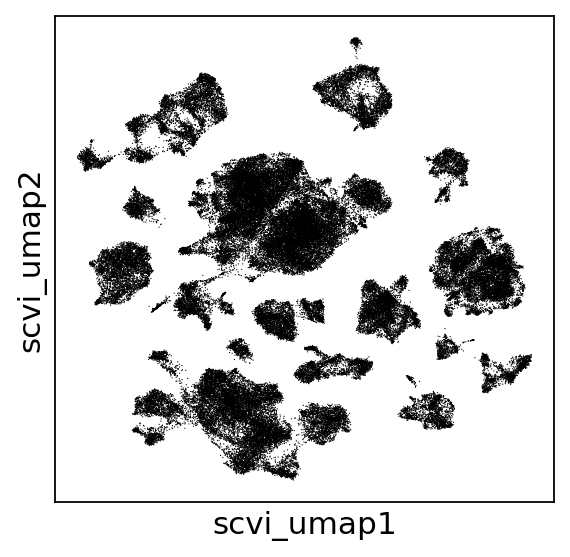

In [10]:
sc.pl.embedding(adata, basis="scvi_umap", na_color="k")

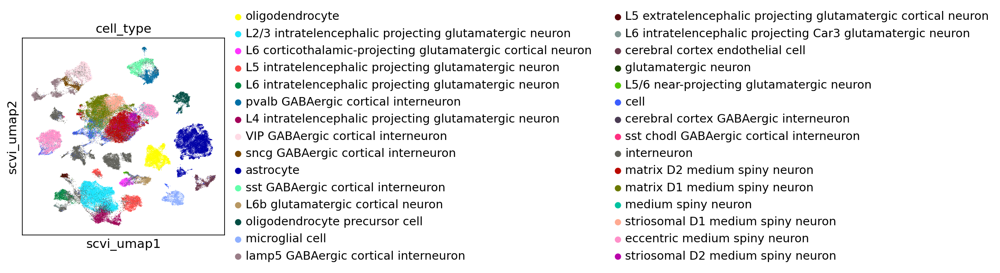

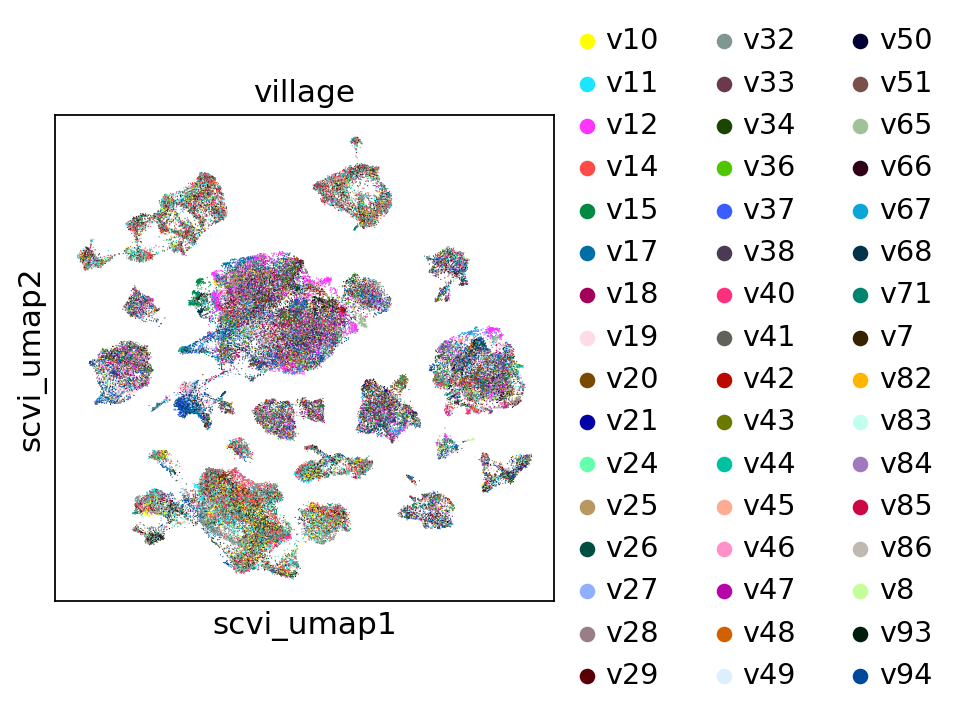

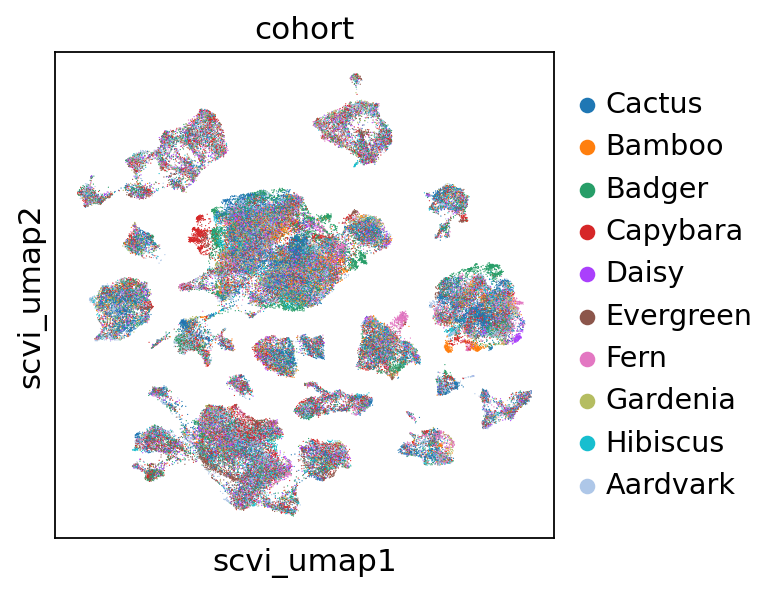

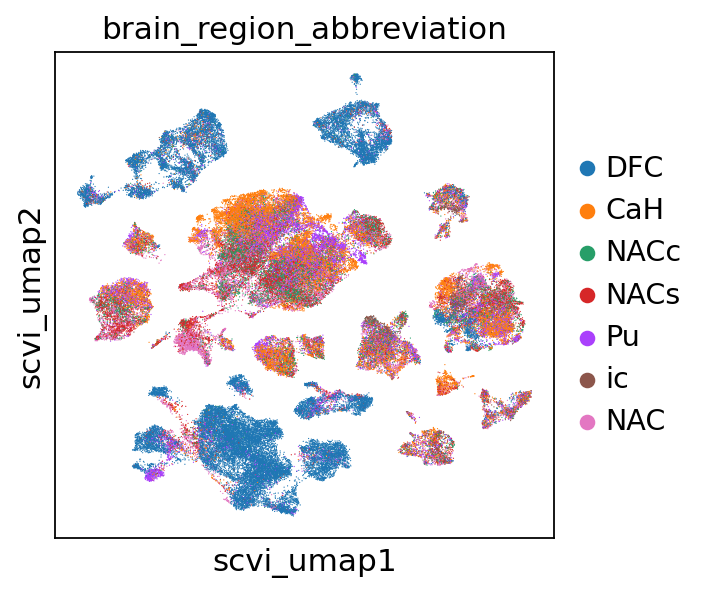

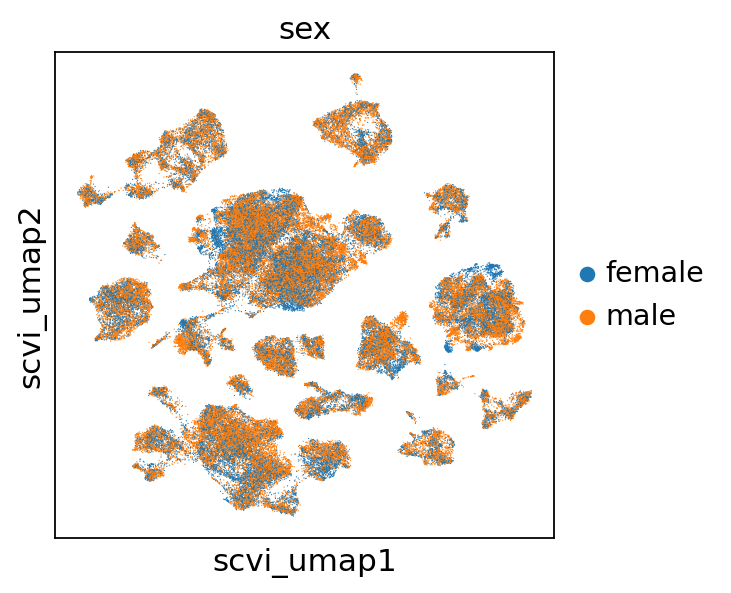

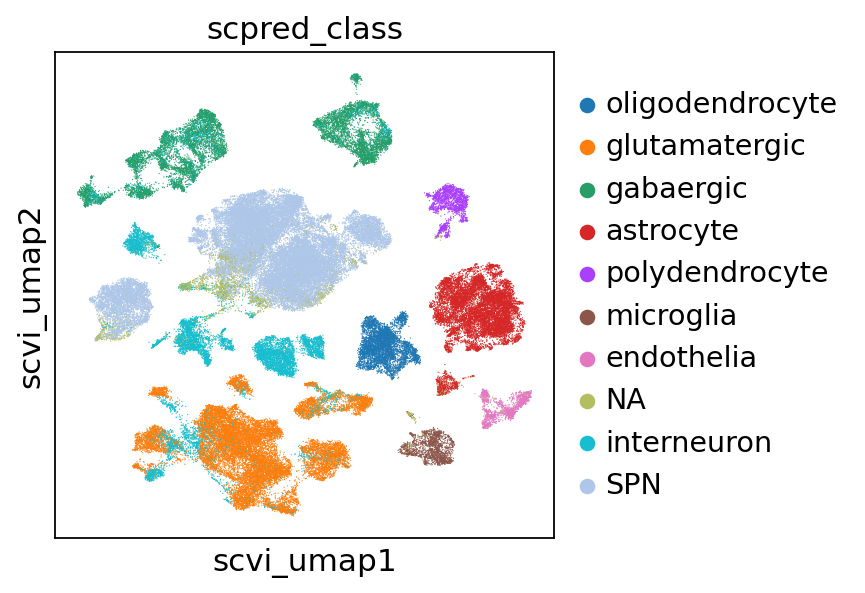

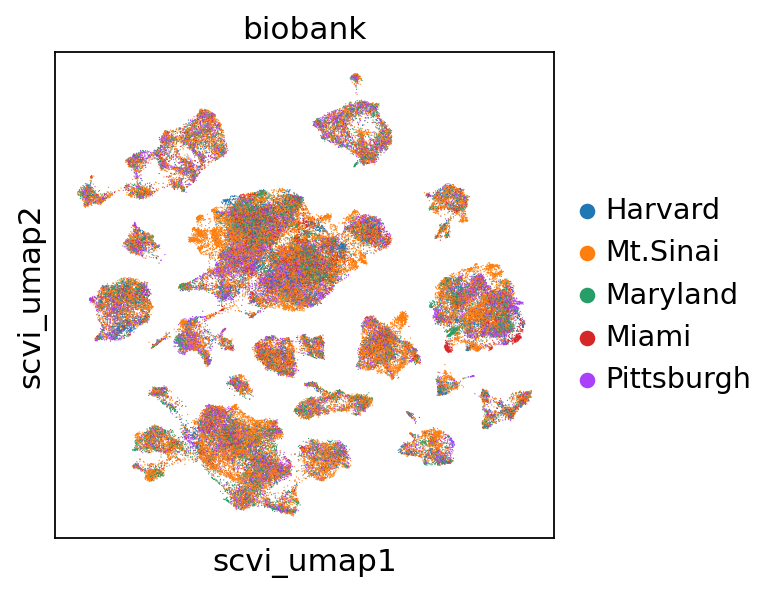

In [11]:
# plot UMAP with a few different values for coloring

for col in ["cell_type", "village", "cohort", "brain_region_abbreviation", "sex", "scpred_class", "biobank"]:
    sc.pl.embedding(adata, basis="scvi_umap", color=col, ncols=1)

## Deep dive on interneurons

In [3]:
cdata = cml.CellariumData.load('/home/sfleming/analysis_sessions/bican/20261030_scvi')
print(cdata)

CellariumData(shape [3857513, 38094], obsm keys: ['X_pca'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=True)
  trained_modules:
    hvg_seurat_v3: HVGSeuratV3(batch_key=None), 2 epochs
    pca: IncrementalPCA(n_components=100, zscore=True, zscore_statistics=normalize_total(target_count=10000, eps=1e-06) > log1p), 1 epochs
    scvi: SingleCellVariationalInference(batch_key=biobank, n_latent=64, val_size=0.1), 74 epochs


In [4]:
cdata_inter = cdata[cdata.obs['cell_type'].isin(['interneuron'])]
print(cdata_inter)

CellariumDataView(shape [154633, 38094], obsm keys: ['X_pca'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=False)
  view of 3857513 cells (the root has 3857513)


In [5]:
# move to memory so everything becomes fast

cdata_inter = cdata_inter.to_ram()

Loading cells into memory: 100%|██████████| 386/386 [02:29<00:00,  2.58block/s]


### Re-run scVI on interneurons

In [6]:
# run highly variable gene selection

cml.pp.highly_variable_genes(
    cdata_inter,
    n_top_genes=4000,
    flavor="seurat_v3",
    accelerator=ACCELERATOR,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1      | train
-------------------------------------------------------
1         Trainable params
0         Non-trainable params
1         Total params
0.000     Total estimated model params size (MB)
3         Modules in train mode
0         Modules in eval mode


Epoch 1: 100%|██████████| 38/38 [00:09<00:00,  4.14it/s]


,highly_variable_rank,variances_norm,highly_variable
gene,,,
TTN,0.0,64.398175,True
ENSG00000250049,1.0,57.104346,True
MEPE,2.0,54.008415,True
EBF1,3.0,47.774604,True
ENSG00000258081,4.0,46.565785,True
...,...,...,...
TRAJ60,NaN,0.000000,False
FAM90A23,NaN,0.000000,False
IGHVII-44-2,NaN,0.000000,False


In [7]:
cml.tl.scvi(
    cdata_inter,
    batch_key="biobank",
    n_latent=64,
    max_epochs=400,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1.1 M  | train
-------------------------------------------------------
1.1 M     Trainable params
0         Non-trainable params
1.1 M     Total params
4.315     Total estimated model params size (MB)
34        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Epoch 322: 100%|██████████| 34/34 [00:03<00:00,  9.74it/s, val_loss=3061.9]


In [8]:
# anndata copy for scanpy plotting

adata_inter = cdata_inter.to_anndata()
print(adata_inter)

Loading cells into memory:   0%|          | 0/16 [00:00<?, ?block/s]

Embedding cells with 'scvi': 100%|██████████| 16/16 [00:30<00:00,  1.88s/chunk]


AnnData object with n_obs × n_vars = 154633 × 38094
    obs: 'age', 'assay', 'biobank', 'brain_region_abbreviation', 'cell_type', 'cell_type_ontology_term_id', 'cohort', 'data_freeze', 'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_external_id', 'donor_id', 'experiment', 'expression_doublet', 'extraction', 'frac_contamination', 'hbcac_status', 'imputed_sex', 'n_counts', 'neuropath_diagnosis', 'num_genes', 'num_genic_reads', 'num_retained_transcripts', 'num_transcripts', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'pct_utr', 'race', 'scpred_class', 'scpred_sub_class', 'sequencing_assay', 'sex', 'suspension_type', 'tissue', 'tissue_ontology_term_id', 'tissue_type', 'village', 'cellarium_cell_id', 'computed_imputed_cell_type', 'computed_imputed_cell_type_propagated', 'computed_imputed_cell_type_propagated_confidence', 'computed_imputed_cell_type_propagated_distance', 'computed_in_sketch', 'computed_leiden', 'computed_leiden_propaga

In [9]:
sc.pp.neighbors(adata_inter, use_rep="X_scvi", method="umap", metric="euclidean")
sc.tl.umap(adata_inter)
adata_inter.obsm["X_scvi_umap"] = adata_inter.obsm["X_umap"].copy()

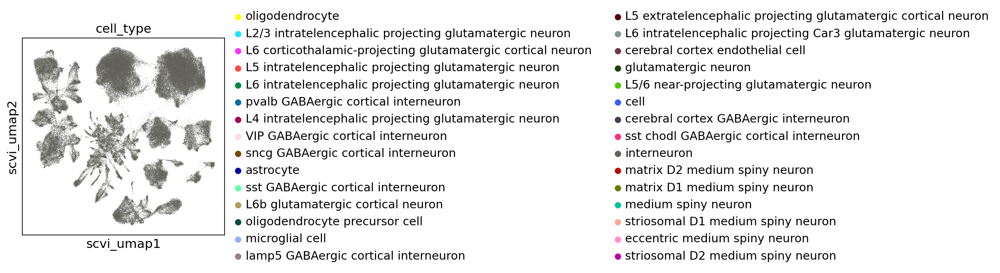

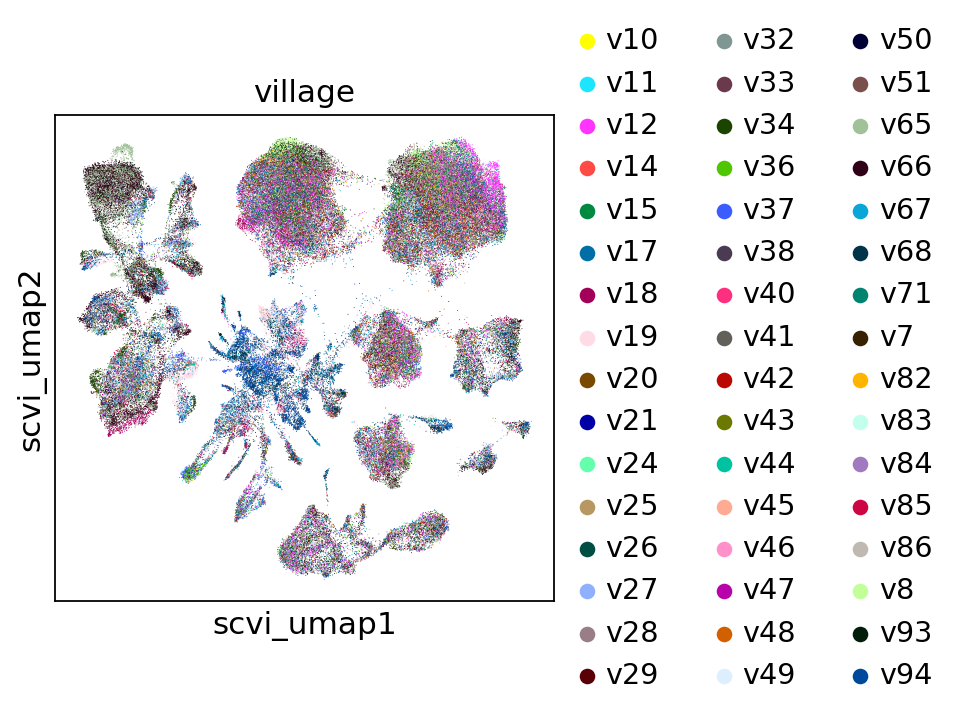

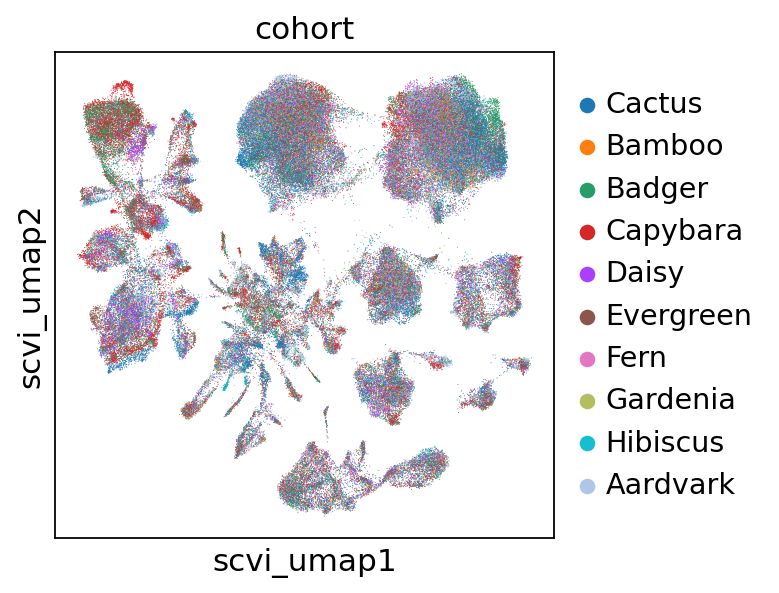

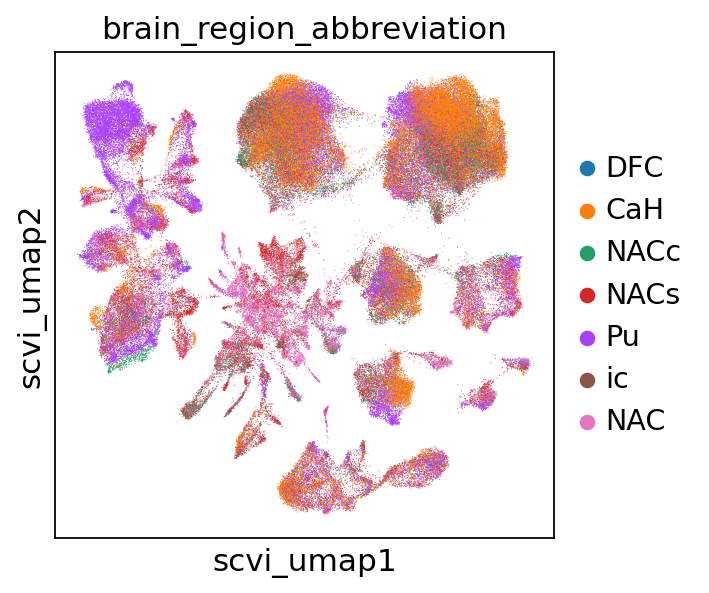

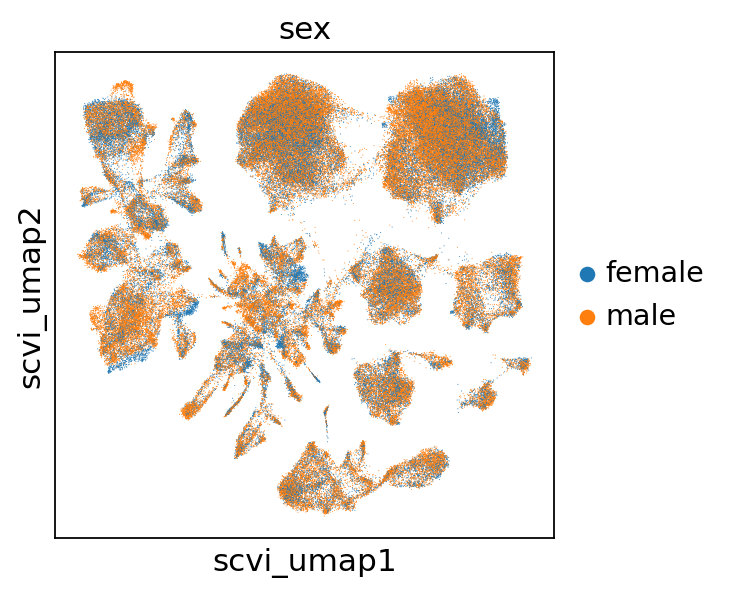

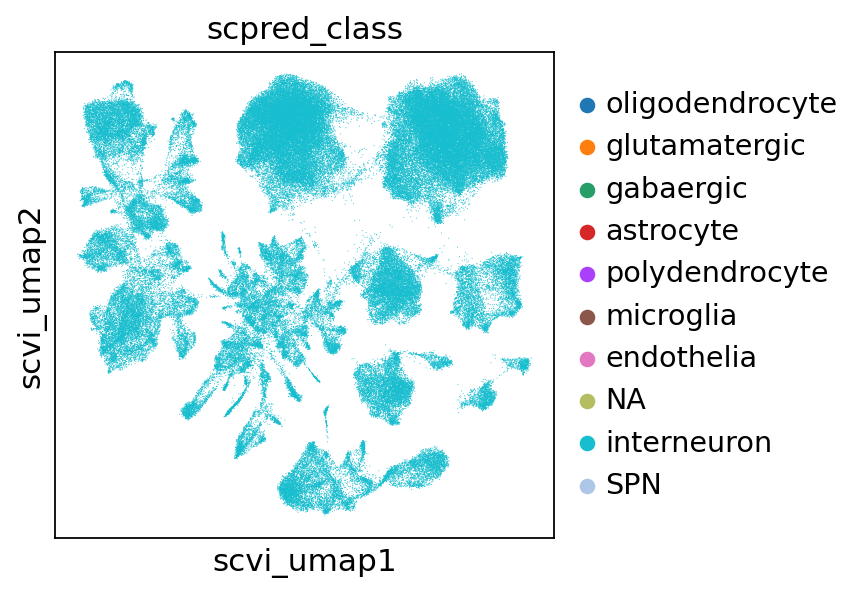

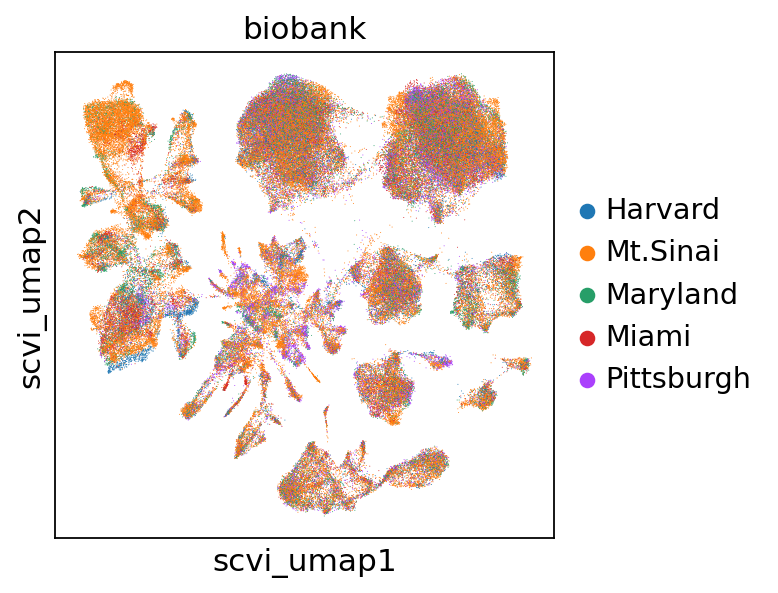

In [10]:
# plot UMAP with a few different values for coloring

for col in ["cell_type", "village", "cohort", "brain_region_abbreviation", "sex", "scpred_class", "biobank"]:
    sc.pl.embedding(adata_inter, basis="scvi_umap", color=col, ncols=1)

### cNMF on interneurons

In [6]:
# compute HVGs as Kotliar does

cml.pp.highly_variable_genes(
    cdata_inter,
    flavor="kotliar",
    n_top_genes=2000,
    normalize_total=True,
    target_count=1e6,
    log1p=False,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1      | train
-------------------------------------------------------
1         Trainable params
0         Non-trainable params
1         Total params
0.000     Total estimated model params size (MB)
4         Modules in train mode
0         Modules in eval mode


Epoch 0: 100%|██████████| 38/38 [00:08<00:00,  4.53it/s]


,mean,var,fano,fano_fit,fano_ratio,highly_variable
MALAT1,23345.193359,1.170261e+08,5012.854980,3588.840332,1.396790,False
KCNIP4,4849.511230,5.902741e+07,12171.827148,787.520935,15.455877,True
RBFOX1,6012.331055,1.170795e+07,1947.322632,963.639343,2.020800,False
PHACTR1,1016.442749,1.081836e+06,1064.335205,206.972046,5.142410,True
PCDH9,2668.911865,8.448533e+06,3165.534668,457.251740,6.922958,True
...,...,...,...,...,...,...
TRAJ60,0.000000,0.000000e+00,NaN,53.023643,NaN,False
FAM90A23,0.000000,0.000000e+00,NaN,53.023643,NaN,False
IGHVII-44-2,0.000000,0.000000e+00,NaN,53.023643,NaN,False
PRR23D2,0.000000,0.000000e+00,NaN,53.023643,NaN,False


In [9]:
nmf_output = cml.tl.cnmf(
    cdata_inter,
    k_values=list(range(5, 40)),
    n_replicates=50,
    max_epochs=3,
    accelerator=ACCELERATOR,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type              | Params | Mode 
-------------------------------------------------------
0 | pipeline | CellariumPipeline | 1.0 M  | train
-------------------------------------------------------
1.0 M     Trainable params
0         Non-trainable params
1.0 M     Total params
4.096     Total estimated model params size (MB)
9         Modules in train mode
0         Modules in eval mode


Epoch 2: 100%|██████████| 38/38 [02:02<00:00,  0.31it/s, rec_error=0.75315, k=5_consensus_q75=0.063695, k=6_consensus_q75=0.052691, k=7_consensus_q75=0.025878, k=8_consensus_q75=0.042084, k=9_consensus_q75=0.042557, k=10_consensus_q75=0.084368, k=11_consensus_q75=0.12751, k=12_consensus_q75=0.12451, k=13_consensus_q75=0.1399, k=14_consensus_q75=0.1179, k=15_consensus_q75=0.1185, k=16_consensus_q75=0.12683, k=17_consensus_q75=0.15353, k=18_consensus_q75=0.14505, k=19_consensus_q75=0.14144, k=20_consensus_q75=0.16732, k=21_consensus_q75=0.18224, k=22_consensus_q75=0.19043, k=23_consensus_q75=0.2003, k=24_consensus_q75=0.20872, k=25_consensus_q75=0.20275, k=26_consensus_q75=0.20436, k=27_consensus_q75=0.20856, k=28_consensus_q75=0.20525, k=29_consensus_q75=0.22661, k=30_consensus_q75=0.20967, k=31_consensus_q75=0.21834, k=32_consensus_q75=0.23428, k=33_consensus_q75=0.23386, k=34_consensus_q75=0.25917, k=35_consensus_q75=0.22988, k=36_consensus_q75=0.2373, k=37_consensus_q75=0.23012, k=38

`Trainer.fit` stopped: `max_epochs=3` reached.


Epoch 2: 100%|██████████| 38/38 [02:02<00:00,  0.31it/s, rec_error=0.75315, k=5_consensus_q75=0.063695, k=6_consensus_q75=0.052691, k=7_consensus_q75=0.025878, k=8_consensus_q75=0.042084, k=9_consensus_q75=0.042557, k=10_consensus_q75=0.084368, k=11_consensus_q75=0.12751, k=12_consensus_q75=0.12451, k=13_consensus_q75=0.1399, k=14_consensus_q75=0.1179, k=15_consensus_q75=0.1185, k=16_consensus_q75=0.12683, k=17_consensus_q75=0.15353, k=18_consensus_q75=0.14505, k=19_consensus_q75=0.14144, k=20_consensus_q75=0.16732, k=21_consensus_q75=0.18224, k=22_consensus_q75=0.19043, k=23_consensus_q75=0.2003, k=24_consensus_q75=0.20872, k=25_consensus_q75=0.20275, k=26_consensus_q75=0.20436, k=27_consensus_q75=0.20856, k=28_consensus_q75=0.20525, k=29_consensus_q75=0.22661, k=30_consensus_q75=0.20967, k=31_consensus_q75=0.21834, k=32_consensus_q75=0.23428, k=33_consensus_q75=0.23386, k=34_consensus_q75=0.25917, k=35_consensus_q75=0.22988, k=36_consensus_q75=0.2373, k=37_consensus_q75=0.23012, k=38

Reconstruction error: 100%|██████████| 38/38 [07:46<00:00, 12.29s/batch]


Epoch 3:   8%|▊         | 3/38 [23:22<4:32:36,  0.00it/s, rec_error=0.75316, k=5_consensus_q75=0.051313, k=6_consensus_q75=0.056576, k=7_consensus_q75=0.015875, k=8_consensus_q75=0.045136, k=9_consensus_q75=0.059285, k=10_consensus_q75=0.091709, k=11_consensus_q75=0.10017, k=12_consensus_q75=0.13746, k=13_consensus_q75=0.13804, k=14_consensus_q75=0.12522, k=15_consensus_q75=0.11409, k=16_consensus_q75=0.11872, k=17_consensus_q75=0.12818, k=18_consensus_q75=0.1348, k=19_consensus_q75=0.14854, k=20_consensus_q75=0.16046, k=21_consensus_q75=0.19239, k=22_consensus_q75=0.18972, k=23_consensus_q75=0.20508, k=24_consensus_q75=0.20121, k=25_consensus_q75=0.20045, k=26_consensus_q75=0.20453, k=27_consensus_q75=0.19913, k=28_consensus_q75=0.2138, k=29_consensus_q75=0.20387, k=30_consensus_q75=0.21154, k=31_consensus_q75=0.2344, k=32_consensus_q75=0.22209, k=33_consensus_q75=0.23534, k=34_consensus_q75=0.22877, k=35_consensus_q75=0.24706, k=36_consensus_q75=0.25534, k=37_consensus_q75=0.2333, k=

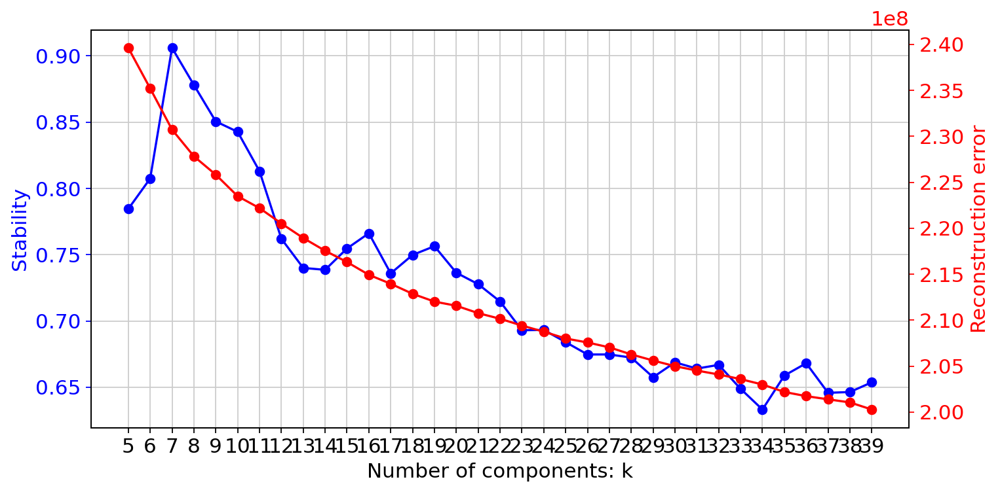

In [10]:
nmf_output.default_k_selection_plot()

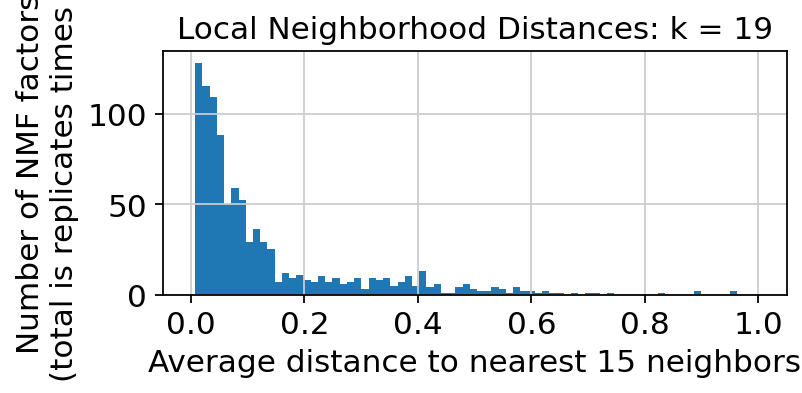

In [11]:
nmf_output.plot_density_histograms(k_values=[19])

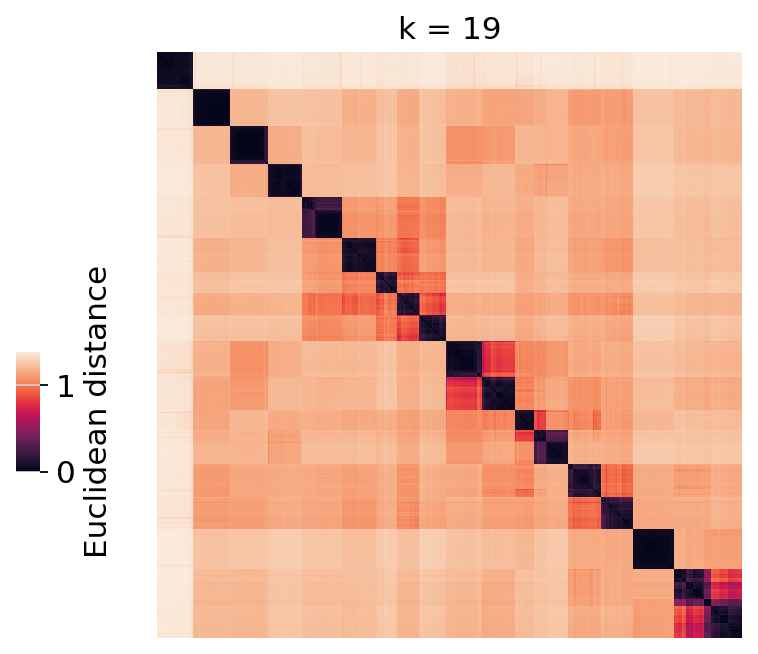

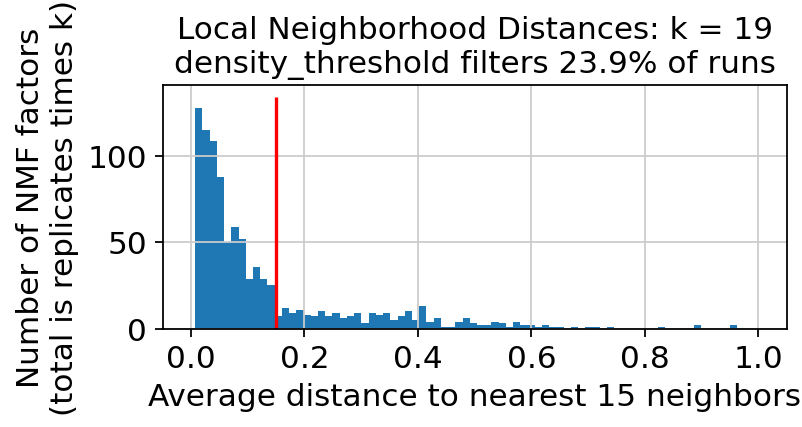

In [26]:
nmf_output.plot_clustermap(k=19, density_threshold=0.15)

In [27]:
d = nmf_output.refit_consensus_factors_zscored_tpm_all_genes(k=19, accelerator=ACCELERATOR)
df_gene_refit = pd.DataFrame(d['factors_kg'].T, index=d['var_names_g'])
df_gene_refit

Refitting k=19:   0%|          | 0/38 [00:00<?, ?batch/s]

Refitting k=19: 100%|██████████| 38/38 [00:35<00:00,  1.08batch/s]


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
MALAT1,-0.004353,0.000586,0.000931,0.000043,-0.000986,0.000921,0.000603,-0.000741,-0.000255,-0.000299,-0.000440,0.000402,0.001248,-0.000350,-0.000223,-0.000910,-0.000057,0.001084,0.000359
KCNIP4,0.000502,0.000501,-0.000363,-0.000506,-0.000550,-0.000724,-0.000240,-0.000170,-0.000691,0.003246,-0.001009,0.001414,-0.000992,0.001028,0.000745,0.000023,-0.000642,-0.000195,-0.000203
RBFOX1,-0.000729,-0.001085,-0.000147,-0.000038,-0.000184,-0.001377,-0.000566,-0.001637,0.000196,0.000299,0.000108,0.000388,0.000690,-0.000478,0.000619,-0.000822,0.000715,-0.000220,0.000488
PHACTR1,0.000379,-0.000476,-0.000291,0.000151,0.001361,-0.000918,-0.000126,-0.000012,0.000128,0.001181,-0.001591,0.000971,-0.000480,0.001408,0.001214,0.000257,-0.001051,-0.000296,-0.000193
PCDH9,0.000820,-0.000320,-0.000315,-0.000789,0.001499,-0.000987,0.000533,-0.000710,-0.000263,0.002266,0.000759,0.000729,-0.001649,0.000837,0.000430,0.000041,0.000038,-0.000390,-0.000355
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TRAJ60,-0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
FAM90A23,-0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
IGHVII-44-2,-0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
PRR23D2,-0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [28]:
for c in df_gene_refit.columns:
    print(c, ': ', end='')
    print(df_gene_refit.sort_values(by=c, ascending=False)[c].head(10).index.tolist())

0 : ['MT-CO1', 'MT-ND5', 'MT-ND4', 'MT-CO3', 'MT-CYB', 'MT-ND2', 'MT-ND4L', 'MT-CO2', 'MT-ND1', 'MT-ATP6']
1 : ['GBX1', 'ADAM7-AS1', 'FGF10', 'INSYN2A', 'FGF10-AS1', 'DIAPH3', 'TNC', 'HS6ST3', 'HTR2C', 'CCDC178']
2 : ['TRPC3', 'CCDC146', 'MEGF10', 'COL6A6', 'SLC5A7', 'NEAT1', 'PRIMA1', 'ENSG00000282142', 'CHAT', 'TSHZ3-AS1']
3 : ['LAMA4', 'NR5A2', 'MOXD1', 'ENSG00000226149', 'P4HA3', 'ARHGAP18', 'PLXNA4', 'LPAR1', 'ADGRA3', 'SFMBT2']
4 : ['HS3ST4', 'TLE4', 'SLC15A5', 'KIAA1217', 'SEMA3E', 'LINC02232', 'VWA2', 'ARSJ', 'ZFPM2', 'ABCC9']
5 : ['NOS1', 'TLL2', 'KCTD8', 'HDAC4', 'DACH1', 'FBN2', 'SOX2-OT', 'SOX6', 'LRP8', 'CRHR2']
6 : ['IGF2BP2', 'MEPE', 'NGFR', 'ENSG00000284977', 'NLRP1', 'COL25A1', 'CD36', 'LUZP2', 'TTN', 'EPHA5-AS1']
7 : ['ENSG00000286778', 'VIP', 'ENSG00000286263', 'ENSG00000289427', 'NPAS3', 'CCNG2', 'SALL1', 'IQGAP2', 'SVEP1', 'CNR1']
8 : ['FBXL7', 'EYA4', 'GOLIM4', 'LAMP5', 'LINC00298', 'IGSF11', 'ARHGAP31', 'MYO16', 'NTNG1', 'FREM1']
9 : ['NR4A2', 'ZNF804B', 'NTNG2',

In [33]:
nmf_output.compute_loadings(k=19, normalize=True, accelerator=ACCELERATOR)

Loadings for k=19: 100%|██████████| 38/38 [00:17<00:00,  2.19batch/s]


In [34]:
print(cdata_inter)

CellariumDataView(shape [154633, 38094], obsm keys: ['X_pca', 'X_cnmf_k10', 'X_cnmf_k19'], obs_computed keys: ['imputed_cell_type', 'imputed_cell_type_propagated', 'imputed_cell_type_propagated_confidence', 'imputed_cell_type_propagated_distance', 'in_sketch', 'leiden', 'leiden_propagated', 'leiden_propagated_confidence', 'leiden_propagated_distance'], hvg_set=True)
  view of 154633 cells (the root has 3857513)
  trained_modules:
    onepass: OnePassMeanVarStd(target_count=1000000.0, eps=1e-06, log1p=False, batch_key=None, normalize_total=True), 1 epochs
    cnmf: AmortizedOnlineNonNegativeMatrixFactorization(k_values=[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39], n_replicates=50, latent_dim=256, max_epochs=3, std_statistics=raw counts), 3 epochs


In [35]:
adata_inter = cdata_inter.to_anndata()
print(adata_inter)

Loading cells into memory:   0%|          | 0/16 [00:00<?, ?block/s]

Loading cells into memory: 100%|██████████| 16/16 [00:07<00:00,  2.11block/s]


AnnData object with n_obs × n_vars = 154633 × 38094
    obs: 'age', 'assay', 'biobank', 'brain_region_abbreviation', 'cell_type', 'cell_type_ontology_term_id', 'cohort', 'data_freeze', 'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_external_id', 'donor_id', 'experiment', 'expression_doublet', 'extraction', 'frac_contamination', 'hbcac_status', 'imputed_sex', 'n_counts', 'neuropath_diagnosis', 'num_genes', 'num_genic_reads', 'num_retained_transcripts', 'num_transcripts', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'pct_utr', 'race', 'scpred_class', 'scpred_sub_class', 'sequencing_assay', 'sex', 'suspension_type', 'tissue', 'tissue_ontology_term_id', 'tissue_type', 'village', 'cellarium_cell_id', 'computed_imputed_cell_type', 'computed_imputed_cell_type_propagated', 'computed_imputed_cell_type_propagated_confidence', 'computed_imputed_cell_type_propagated_distance', 'computed_in_sketch', 'computed_leiden', 'computed_leiden_propaga

In [36]:
k = 19

adata_inter.obsm[f'X_cnmf_k{k}'] = cdata_inter.obsm[f'X_cnmf_k{k}'].copy()
for c in range(adata_inter.obsm[f'X_cnmf_k{k}'].shape[1]):
    adata_inter.obs[f'cnmf_{c}_loading'] = adata_inter.obsm[f'X_cnmf_k{k}'][:, c]
print(adata_inter)

AnnData object with n_obs × n_vars = 154633 × 38094
    obs: 'age', 'assay', 'biobank', 'brain_region_abbreviation', 'cell_type', 'cell_type_ontology_term_id', 'cohort', 'data_freeze', 'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_external_id', 'donor_id', 'experiment', 'expression_doublet', 'extraction', 'frac_contamination', 'hbcac_status', 'imputed_sex', 'n_counts', 'neuropath_diagnosis', 'num_genes', 'num_genic_reads', 'num_retained_transcripts', 'num_transcripts', 'pct_intergenic', 'pct_intronic', 'pct_mt', 'pct_utr', 'race', 'scpred_class', 'scpred_sub_class', 'sequencing_assay', 'sex', 'suspension_type', 'tissue', 'tissue_ontology_term_id', 'tissue_type', 'village', 'cellarium_cell_id', 'computed_imputed_cell_type', 'computed_imputed_cell_type_propagated', 'computed_imputed_cell_type_propagated_confidence', 'computed_imputed_cell_type_propagated_distance', 'computed_in_sketch', 'computed_leiden', 'computed_leiden_propaga

In [23]:
sc.pp.neighbors(adata_inter, use_rep='X_pca', n_neighbors=15, method='umap', metric='cosine')
sc.tl.umap(adata_inter)

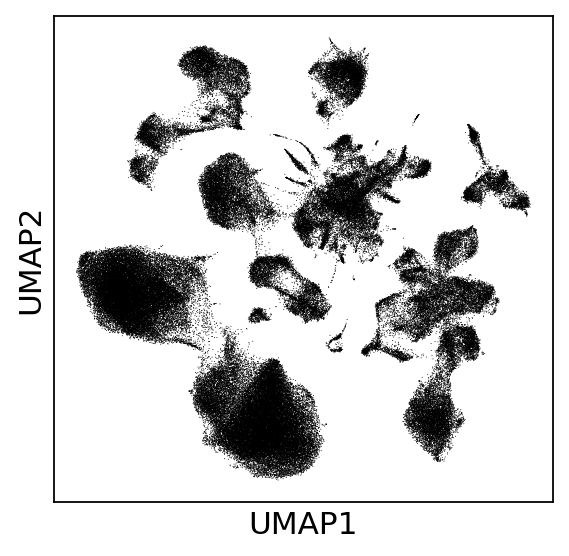

In [24]:
sc.pl.embedding(adata_inter, basis='umap', na_color='k')

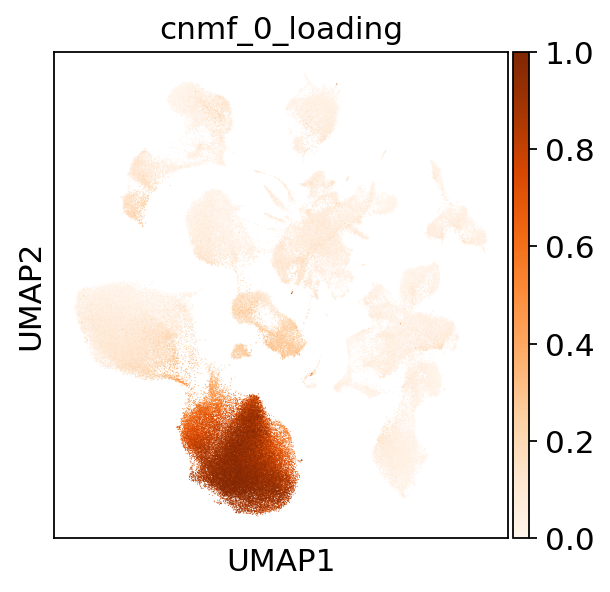

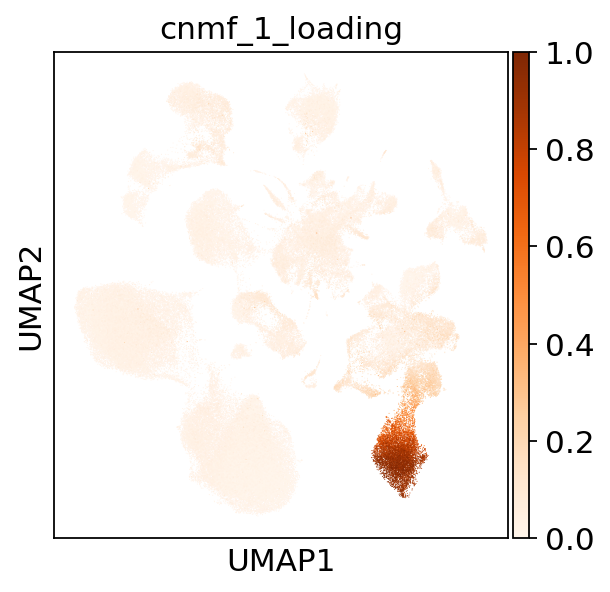

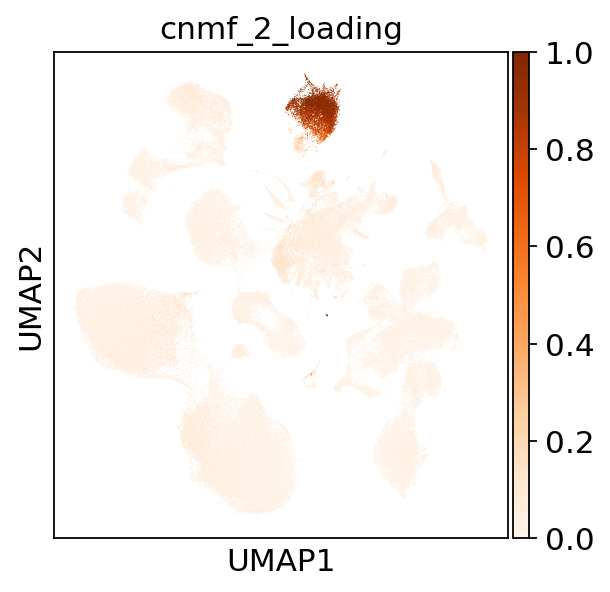

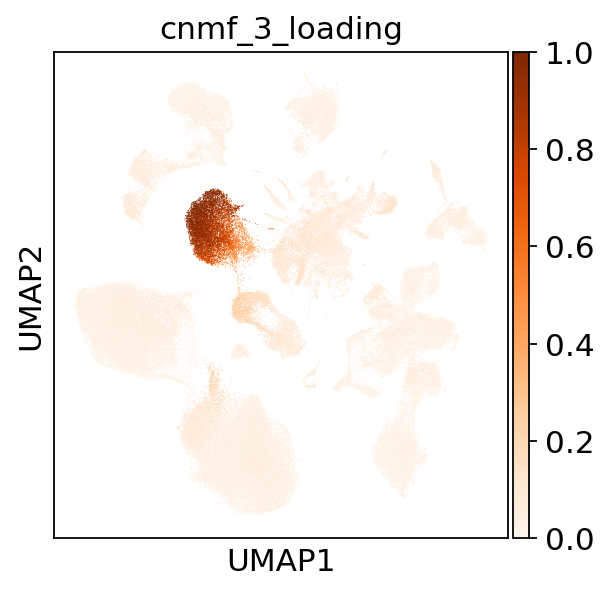

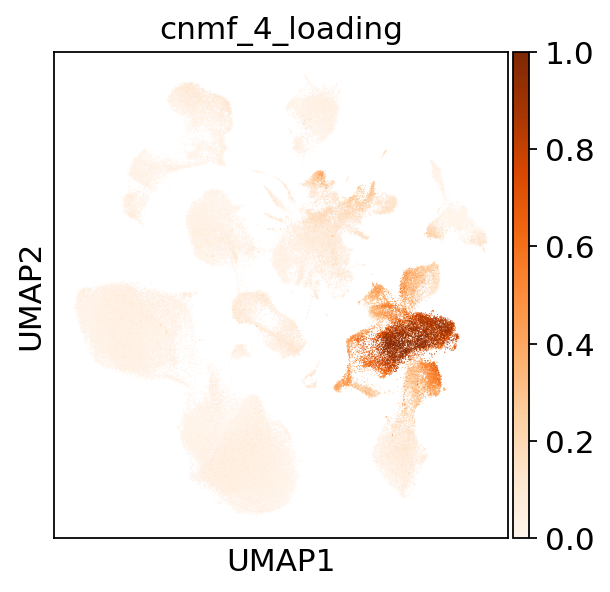

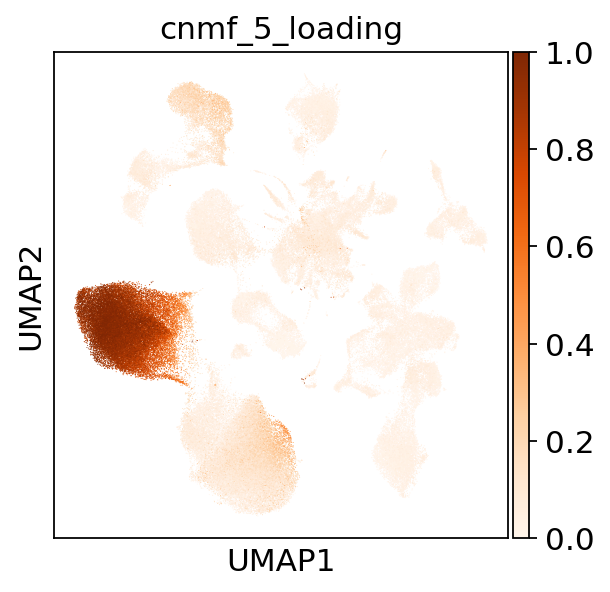

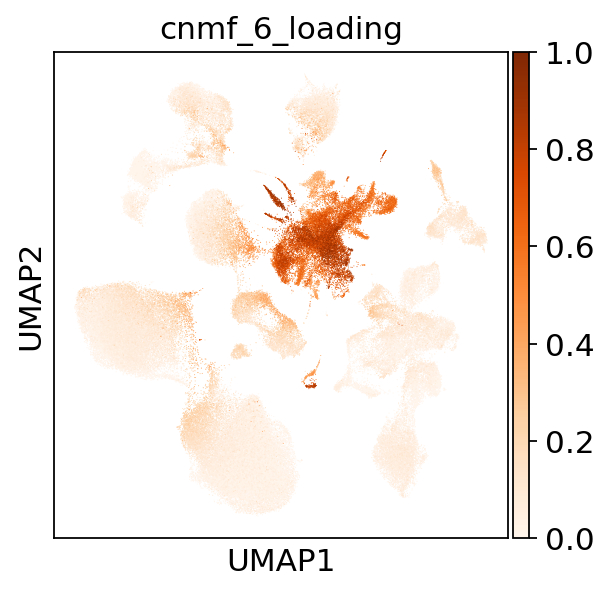

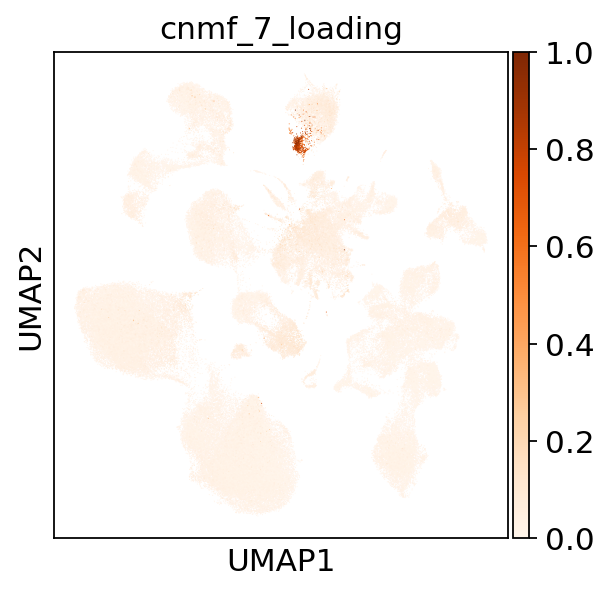

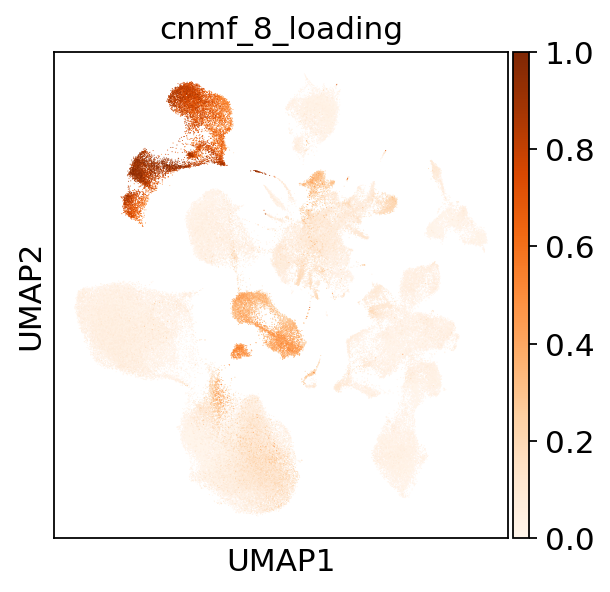

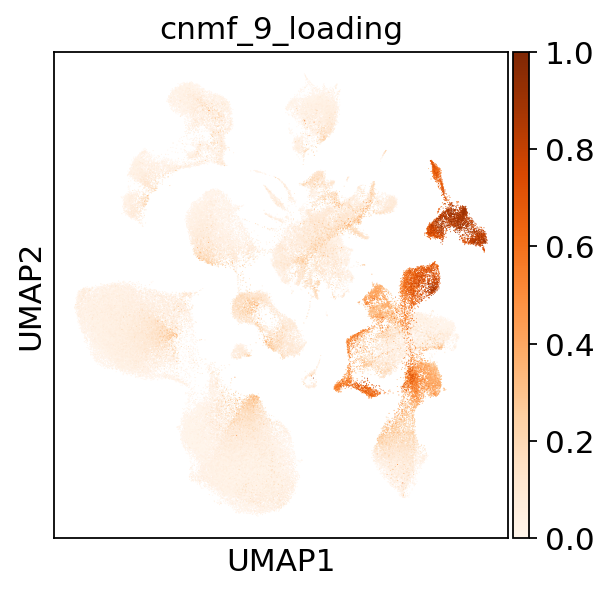

In [25]:
for c in [col for col in adata_inter.obs.columns if col.startswith('cnmf_')]:
    sc.pl.embedding(adata_inter, basis='umap', color=c, color_map='Oranges')